# 제안서용 핵심 근거: 타겟은 몇 명이고, 돈이 되고, 갚을 수 있고, 남을 사람들인가

앞의 두 노트북(`foreign_entrepreneur_finance`, `children_hypothesis`)이 만든 가공 데이터를 다시 써서
공모전 제안서에 바로 들어갈 **네 가지 질문**에 답한다.

| # | 질문 | 이 노트북의 답 방식 |
|---|---|---|
| Q1 | 타겟층(외국인 사장님)은 실제로 **몇 명**인가 | 하한·중심·상한 3중 추정 + 예비 사장님 풀 + 2028 전망 + 지역 집중도 |
| Q2 | **돈이 되는** 시장인가 | 1인당 종합소득세 추이, 송금 규모, 보수·기준·낙관 수익 시나리오와 민감도 |
| Q3 | **상환능력**이 있는가 | 체류자격별 소득분포로 DSR 40% 통과 비율 추정, 공과금 미납(연체 대리) |
| Q4 | **거주민이 될(남을) 사람들**인가 | 체류자격 단위·시군구 단위 상관 (사업 가능 외국인 비중 ↔ 10년+ 체류·국적취득) |

입력은 `data/processed/`, `data/curated/`의 CSV뿐이라 몇 초 안에 재실행된다. 가정값은 모두 `ASSUME`에 모았다.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

from src import viz as V
V.setup()
mpl.rcParams["font.family"] = ["Malgun Gothic", "Noto Sans CJK KR", "sans-serif"]  # 윈도우=맑은고딕
C, SERIES, BLUE = V.C, V.SERIES, V.BLUE

FIG = ROOT / "figures"; PROC = ROOT / "data" / "processed"; CUR = ROOT / "data" / "curated"
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

from src import load as L, metrics as M
survey = L.load_survey()   # KOSIS 통계표(모든 연도). 손으로 옮긴 CSV와 반올림 범위 안에서 같다
def sv(table, year=None):
    d = survey[survey.table == table]
    return d if year is None else d[d.year == year]
es = sv("employment_status").pivot(index="year", columns="category", values="value")  # 천 명
nts = pd.read_csv(PROC / "nts_foreign_income_tax.csv")
vts = pd.read_csv(PROC / "visa_group_timeseries.csv", parse_dates=["date"]).set_index("date")
visa = pd.read_csv(PROC / "visa_indicators_2025.csv")
rem = pd.read_csv(PROC / "remittances_paid_korea.csv")

### 가정값 (발표 때 근거와 함께 제시, 바꾸면 전부 재계산)

In [2]:
ASSUME = {
    # 외부 비교값: 국가데이터처 2025.8 경제활동인구조사 비임금근로 부가조사
    "내국인 포함 전체 자영업자 비중(2025.8)": 0.196,   # (143.5만+424.1만)/취업자(655.4만/0.226)
    "신한카드 외국인 개인사업자 가맹점": 10_323,       # 이민정책연구원 통계브리프 2025-14
    # 대출 조건 (DSR 계산용)
    "대출금리(연)": 0.06, "대출기간(월)": 60, "DSR 한도": 0.40,
    # 수익 시나리오: (보수, 기준, 낙관)
    "침투율": (0.03, 0.05, 0.10),
    "평균 대출액(만원)": (2000, 3000, 5000),
    "예대마진": (0.030, 0.035, 0.040),
    "대손비용률": (0.015, 0.010, 0.007),
    "송금 수수료율": (0.005, 0.010, 0.015),
    "송금 침투율": (0.03, 0.05, 0.10),
    "송금액 구간 대표값(만원)": [50, 150, 250, 400, 750, 1250, 1750, 2500],
}

---
## Q1. 타겟층은 실제로 몇 명인가
외국인 사장님 수를 직접 세는 공개 통계는 없어서, 정의가 다른 세 개 자료로 **범위**를 잡는다.

| 구분 | 자료 | 의미 |
|---|---|---|
| 하한 | 신한카드 외국인 개인사업자 가맹점 10,323곳 | 카드 단말기를 단 '확인된' 사장님 (한 카드사 기준이라 과소) |
| **중심** | 이민자체류실태조사 자영업자(고용주 + 1인) | 무급가족 제외 실제 사장님 — **제안서 대표 숫자** |
| 상한 | 국세청 외국인 종합소득세 신고자 | 사업·프리랜서 등 종합소득이 있는 외국인 (사장님 아닌 사람 포함) |
| 예비 | 사업자등록 가능 체류자격(F-2·F-4·F-5·F-6·D-8·D-9) 체류자 | 지금 당장 창업할 수 있는 잠재 고객 풀 |

In [3]:
# 중심 추정은 KOSIS 통계표(DT_2FB007F, 2012~2025, 소수 첫째 자리 천 명)를 쓴다. 계산은 src/metrics.py와 같은 함수다.
from src import metrics as M, load as L
se = L.load_self_employed_series().set_index("year")   # employer, solo, total (명)
emp_core = se.total
cagr_rng = M.core_cagr_range()     # trend(2012~2025 로그선형 추세) / endpoint(2012→2025) / recent3(2022→2025)
cagr_core = cagr_rng["trend"]      # 대표값: 14년 전체를 쓰는 추세 증가율
cagr_nts = (nts.set_index("year").filers[2024] / nts.set_index("year").filers[2014]) ** (1 / 10) - 1
biz_pool = vts["사업 가능 체류자격 합계"].iloc[-1]
cagr_biz = (vts["사업 가능 체류자격 합계"].iloc[-1] / vts["사업 가능 체류자격 합계"].iloc[0]) ** (
    1 / ((vts.index[-1] - vts.index[0]).days / 365.25)) - 1

core_2028 = emp_core[2025] * (1 + cagr_core) ** 3
counts = pd.DataFrame([
    ("하한", "신한카드 외국인 개인사업자 가맹점", ASSUME["신한카드 외국인 개인사업자 가맹점"], "2025 브리프", np.nan),
    ("중심", "외국인 자영업자(고용주+1인)", emp_core[2025], "2025.5", cagr_core),
    ("  └ 고용원 있는 사장님", "직원을 둔 외국인 사장님", se.employer[2025], "2025.5",
     np.exp(np.polyfit(se.index.values, np.log(se.employer.values), 1)[0]) - 1),
    ("상한", "외국인 종합소득세 신고자", nts.filers.iloc[-1], "2024", cagr_nts),
    ("예비", "사업 가능 체류자격 체류자", biz_pool, "2026.9", cagr_biz),
], columns=["구분", "정의", "인원", "기준시점", "연평균 증가율"])
counts.to_csv(PROC / "target_counts.csv", index=False)
print(counts.assign(인원=counts.인원.map("{:,.0f}".format),
                    **{"연평균 증가율": counts["연평균 증가율"].map(lambda v: "" if pd.isna(v) else f"{v:.1%}")}).to_string(index=False))
print(f"\n중심 추정 2028 전망 (2012~2025 추세 증가율 {cagr_core:.1%} 유지): {core_2028:,.0f}명")
print("계산법별 증가율과 2028 전망: " + " · ".join(
    f"{lab} {cagr_rng[k]:.1%} → {emp_core[2025] * (1 + cagr_rng[k]) ** 3 / 1e4:.2f}만 명"
    for k, lab in (("endpoint", "2012→2025 단순"), ("recent3", "최근 3년"), ("trend", "14년 추세"))))

            구분                 정의        인원     기준시점 연평균 증가율
            하한 신한카드 외국인 개인사업자 가맹점    10,323 2025 브리프        
            중심   외국인 자영업자(고용주+1인)    55,900   2025.5    9.4%
  └ 고용원 있는 사장님      직원을 둔 외국인 사장님    18,200   2025.5    9.0%
            상한      외국인 종합소득세 신고자   253,050     2024   17.8%
            예비     사업 가능 체류자격 체류자 1,090,886   2026.9    5.2%

중심 추정 2028 전망 (2012~2025 추세 증가율 9.4% 유지): 73,213명
계산법별 증가율과 2028 전망: 2012→2025 단순 8.6% → 7.15만 명 · 최근 3년 9.0% → 7.23만 명 · 14년 추세 9.4% → 7.32만 명


### 1-1b. 14년 추이 — 외국인 사장님은 2012년 1.9만 명에서 2025년 5.6만 명으로 늘었다
표본조사라 해마다 출렁인다(2013년 감소 등). 그래서 증가율은 한두 해가 아니라 14년 전체 추세로 잡는다.
귀화허가자와 무급가족종사자는 넣지 않았다.

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (614 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


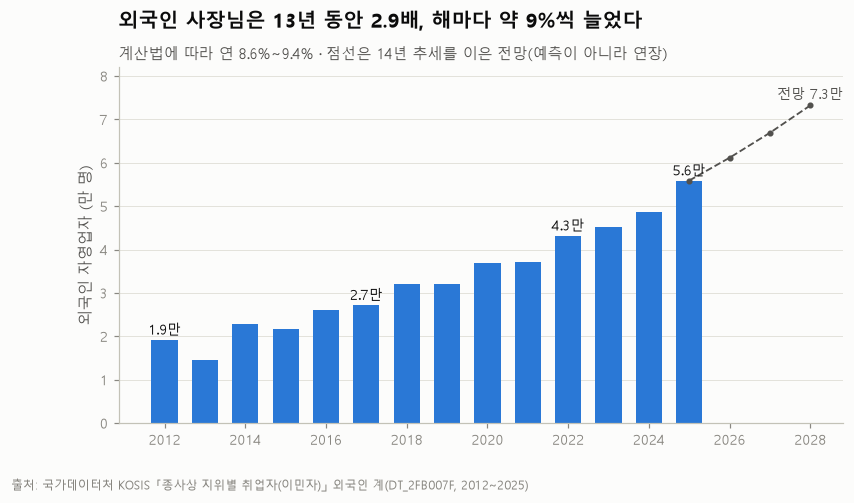

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(se.index, se.total / 1e4, color=SERIES[0], width=0.65)
for y in (2012, 2017, 2022, 2025):
    ax.text(y, se.total[y] / 1e4 + 0.12, f"{se.total[y]/1e4:.1f}만", ha="center", fontsize=9, color=C["ink"])
yy = np.array([2025, 2026, 2027, 2028])
ax.plot(yy, emp_core[2025] * (1 + cagr_core) ** (yy - 2025) / 1e4, color=C["ink2"], lw=1.2, ls="--", marker="o", ms=3)
ax.text(2028, core_2028 / 1e4 + 0.15, f"전망 {core_2028/1e4:.1f}만", ha="center", fontsize=9, color=C["ink2"])
ax.set_xticks(list(range(2012, 2029, 2))); ax.set_ylim(0, 8.2)
ax.set_ylabel("외국인 자영업자 (만 명)"); ax.grid(axis="x", visible=False)
ax.set_title(f"외국인 사장님은 13년 동안 {se.total[2025]/se.total[2012]:.1f}배, 해마다 약 {cagr_core:.0%}씩 늘었다")
V.subtitle(ax, f"계산법에 따라 연 {min(cagr_rng[k] for k in ('trend','endpoint','recent3')):.1%}~"
               f"{max(cagr_rng[k] for k in ('trend','endpoint','recent3')):.1%} · 점선은 14년 추세를 이은 전망(예측이 아니라 연장)")
V.finish(fig, FIG / "t08_self_employed_trend.png", "국가데이터처 KOSIS 「종사상 지위별 취업자(이민자)」 외국인 계(DT_2FB007F, 2012~2025)")

### 1-2. 잠재 창업 여력 — 외국인 자영업률은 내국인의 1/4
사업 가능 체류자격 취업자(F-4·F-5·F-6 + 기타)를 분모로 해도 외국인 자영업률은 내국인보다 한참 낮다.
이 격차만큼은 '자금·금융 접근만 풀리면 창업할 수 있는' 잠재 수요로 본다 (단순 격차 추정, 상한 성격).

In [5]:
emp_by_visa = sv("employed_by_visa", 2025).set_index("category").value * 1e3
emp_total = es.loc[2025, "취업자"] * 1e3
emp_elig = emp_by_visa[["재외동포(F-4)", "영주(F-5)", "결혼이민(F-6)"]].sum()  # F-2·D-8·D-9는 '기타'에 섞여 제외(보수적)
rate_all = emp_core[2025] / emp_total
rate_elig = emp_core[2025] / emp_elig   # 자영업자 대부분이 사업 가능 자격자라는 가정 → 상한
kr = ASSUME["내국인 포함 전체 자영업자 비중(2025.8)"]
latent = (kr - rate_elig) * emp_elig
print(f"외국인 취업자 {emp_total:,.0f}명 중 자영업 {rate_all:.1%}")
print(f"사업 가능 자격(F-4·F-5·F-6) 취업자 {emp_elig:,.0f}명 기준 자영업률 ≤ {rate_elig:.1%}  vs 전체 {kr:.1%}")
print(f"→ 격차를 메우면 추가로 생길 사장님 ≈ {latent:,.0f}명 (잠재 창업 수요)")

외국인 취업자 1,109,300명 중 자영업 5.0%
사업 가능 자격(F-4·F-5·F-6) 취업자 453,900명 기준 자영업률 ≤ 12.3%  vs 전체 19.6%
→ 격차를 메우면 추가로 생길 사장님 ≈ 33,064명 (잠재 창업 수요)


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (322 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


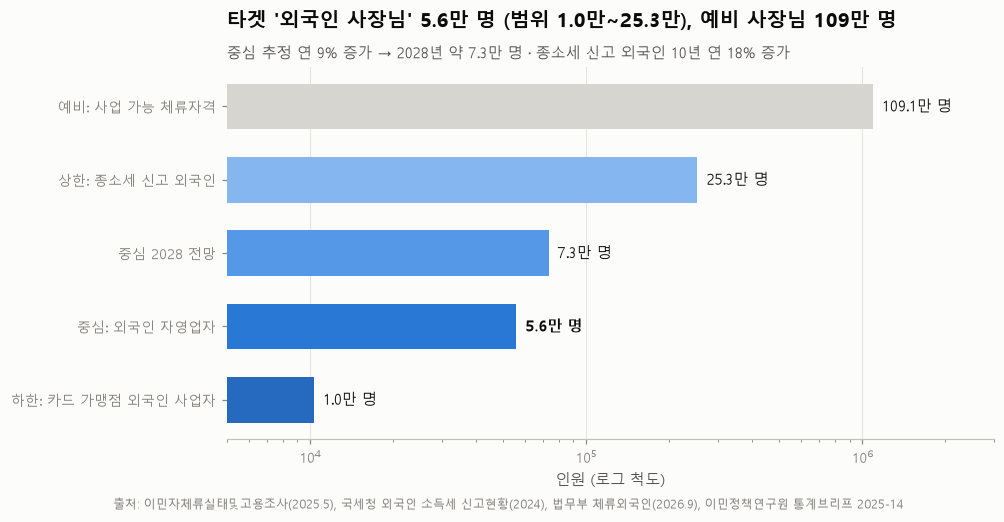

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.4))
rows = [("예비: 사업 가능 체류자격", biz_pool, C["neutral"]),
        ("상한: 종소세 신고 외국인", nts.filers.iloc[-1], BLUE[3]),
        ("중심 2028 전망", core_2028, BLUE[5]),
        ("중심: 외국인 자영업자", emp_core[2025], SERIES[0]),
        ("하한: 카드 가맹점 외국인 사업자", ASSUME["신한카드 외국인 개인사업자 가맹점"], BLUE[8])][::-1]
for i, (lab, v, col) in enumerate(rows):
    ax.barh(i, v, color=col, height=0.62)
    ax.text(v * 1.08, i, f"{v/1e4:,.1f}만 명", va="center", fontsize=10, color=C["ink"],
            fontweight="bold" if "중심: " in lab else "normal")
ax.set_xscale("log"); ax.set_xlim(5e3, 3e6)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows])
ax.set_xlabel("인원 (로그 척도)"); ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
ax.set_title(f"타겟 '외국인 사장님' 5.6만 명 (범위 1.0만~25.3만), 예비 사장님 {biz_pool/1e4:.0f}만 명")
V.subtitle(ax, f"중심 추정 연 {cagr_core:.0%} 증가 → 2028년 약 {core_2028/1e4:.1f}만 명 · 종소세 신고 외국인 10년 연 {cagr_nts:.0%} 증가")
V.finish(fig, FIG / "t01_target_count_range.png",
         "이민자체류실태및고용조사(2025.5), 국세청 외국인 소득세 신고현황(2024), 법무부 체류외국인(2026.9), 이민정책연구원 통계브리프 2025-14")

### 1-3. 어디에 있나 — 상위 시군구 집중도

  label       biz    총합계   LQ  누적비중
 경기 안산시 76,454.00 101718 1.58  0.07
 경기 시흥시 54,282.00  73839 1.55  0.12
 경기 수원시 48,769.00  67822 1.52  0.17
 경기 부천시 45,203.00  56908 1.67  0.21
 서울 구로구 43,746.00  50264 1.83  0.25
서울 영등포구 42,207.00  49086 1.81  0.29
 경기 화성시 28,152.00  71500 0.83  0.31
 인천 부평구 27,197.00  32019 1.79  0.34
 경기 평택시 25,173.00  52756 1.01  0.36
 서울 금천구 25,153.00  28899 1.83  0.38

상위 10개 시군구 = 사업 가능 외국인의 38%, 상위 20개 = 55% (전체 228개 시군구 중)


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (615 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


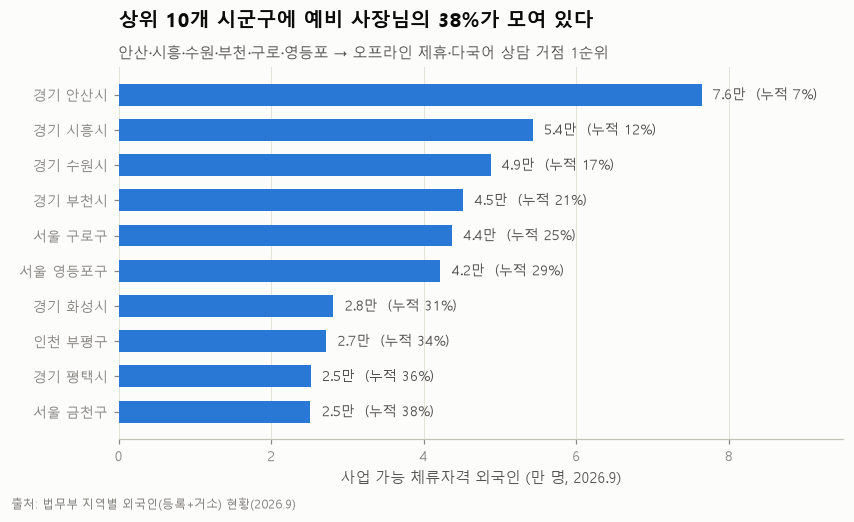

In [7]:
reg = pd.read_csv(PROC / "region_business_eligible.csv")
reg = reg.sort_values("biz", ascending=False).reset_index(drop=True)
reg["누적비중"] = reg.biz.cumsum() / reg.biz.sum()
top10 = reg.head(10)
print(top10[["label", "biz", "총합계", "LQ", "누적비중"]].to_string(index=False))
print(f"\n상위 10개 시군구 = 사업 가능 외국인의 {reg.누적비중.iloc[9]:.0%}, 상위 20개 = {reg.누적비중.iloc[19]:.0%}"
      f" (전체 {len(reg)}개 시군구 중)")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
d = top10.iloc[::-1]
ax.barh(d.label, d.biz / 1e4, color=SERIES[0], height=0.62)
for i, (v, cum) in enumerate(zip(d.biz, d.누적비중)):
    ax.text(v / 1e4 + 0.15, i, f"{v/1e4:.1f}만  (누적 {cum:.0%})", va="center", fontsize=9, color=C["ink2"])
ax.set_xlim(0, 9.5); ax.set_xlabel("사업 가능 체류자격 외국인 (만 명, 2026.9)")
ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
ax.set_title(f"상위 10개 시군구에 예비 사장님의 {reg.누적비중.iloc[9]:.0%}가 모여 있다")
V.subtitle(ax, "안산·시흥·수원·부천·구로·영등포 → 오프라인 제휴·다국어 상담 거점 1순위")
V.finish(fig, FIG / "t02_target_top_regions.png", "법무부 지역별 외국인(등록+거소) 현황(2026.9)")

### 1-3b. 시도별 사장님 전환 지수 — 예비 사장님은 많은데 가게는 적은 곳
시도마다 **예비 사장님(사업 가능 체류자격) 1만 명당 외국인 카드 가맹점 수**를 비교한다(전국 = 100).
- 가맹점: 통계브리프 표 5(신한카드, 2025.6, 해지 포함). 예비 사장님: 법무부(2026.9). 광주·전남은 2026년 통합 행정구역에 맞춰 합쳤다.
- 시점·대상이 다르고 한 카드사 기준이라 **전환율이 아니라 상대 지수**다. 관광지가 많은 곳은 외국인 관광객 상대 가게가 섞여 높게 나올 수 있다.

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (925 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


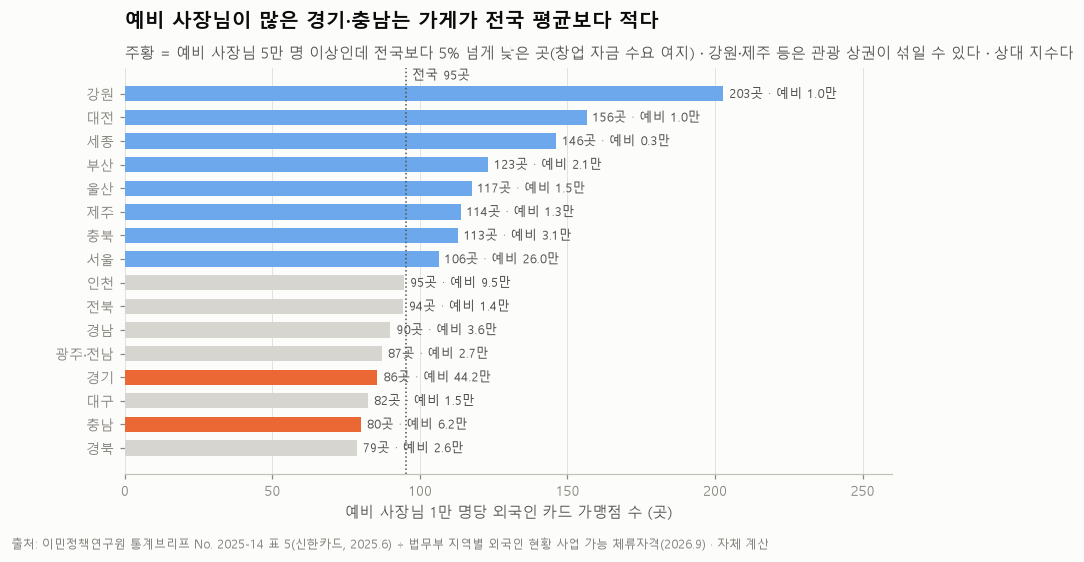

In [8]:
pc = pd.DataFrame(M.province_conversion()).set_index("sido")
print(pc[["merchants", "business_eligible", "per_10k", "index"]].round(1).to_string())
fig, ax = plt.subplots(figsize=(9, 4.8))
d = pc.iloc[::-1]
cols = [SERIES[1] if (r.business_eligible >= 5e4 and r["index"] < 95) else (BLUE[4] if r["index"] >= 100 else C["neutral"])
        for _, r in d.iterrows()]
ax.barh(d.index, d.per_10k, color=cols, height=0.65)
nat_pc = pc.merchants.sum() / pc.business_eligible.sum() * 1e4
ax.axvline(nat_pc, color=C["ink2"], lw=1, ls=":")
ax.text(nat_pc + 2, len(d) - 0.4, f"전국 {nat_pc:.0f}곳", fontsize=8.5, color=C["ink2"])
for i, (k, r) in enumerate(d.iterrows()):
    ax.text(r.per_10k + 2, i, f"{r.per_10k:.0f}곳 · 예비 {r.business_eligible/1e4:.1f}만", va="center", fontsize=8.5, color=C["ink2"])
ax.set_xlim(0, 260); ax.set_xlabel("예비 사장님 1만 명당 외국인 카드 가맹점 수 (곳)"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
big_low = pc[(pc.business_eligible >= 5e4) & (pc["index"] < 95)]
ax.set_title(f"예비 사장님이 많은 {'·'.join(big_low.index)}는 가게가 전국 평균보다 적다")
V.subtitle(ax, f"주황 = 예비 사장님 5만 명 이상인데 전국보다 5% 넘게 낮은 곳(창업 자금 수요 여지) · 강원·제주 등은 관광 상권이 섞일 수 있다 · 상대 지수다")
V.finish(fig, FIG / "t18_province_conversion.png",
         "이민정책연구원 통계브리프 No. 2025-14 표 5(신한카드, 2025.6) ÷ 법무부 지역별 외국인 현황 사업 가능 체류자격(2026.9) · 자체 계산")

### 1-4. 사장님은 누구인가 — 카드 가맹점 10,323곳으로 본 국적·업종·매출
조사 통계(KOSIS)는 자영업자를 성별로만 나눈다. 그래서 사장님의 국적·업종·매출은
이민정책연구원 통계브리프 No. 2025-14(신한카드 외국인 개인사업자 가맹점, 2025년 6월 말)로 본다.
- 한 카드사 자료라 전체 외국인 사장님을 대표하지 않는다. 체류자격 정보가 없다.
- 10,323곳은 2024.1~2025.6에 매출이 있던 곳이고, 이 가운데 2,288곳(22%)은 자료 제공 시점에 가맹 해지 상태다.
- 업종 분류는 카드사 자체 기준이다.

중국        72.50
기타 아시아     7.50
미국         6.20
캐나다        3.70
대만         3.10
유럽         2.80
그 밖의 국적    4.30
요식/유흥     61.40
미용        11.10
음/식료품      5.90
교육/학원      3.90
의료         3.60
유통         2.90
그 밖의 업종   11.00
수도권 72.2% · 영업 중 8,035곳 / 해지 2,288곳(22.2%)


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (817 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


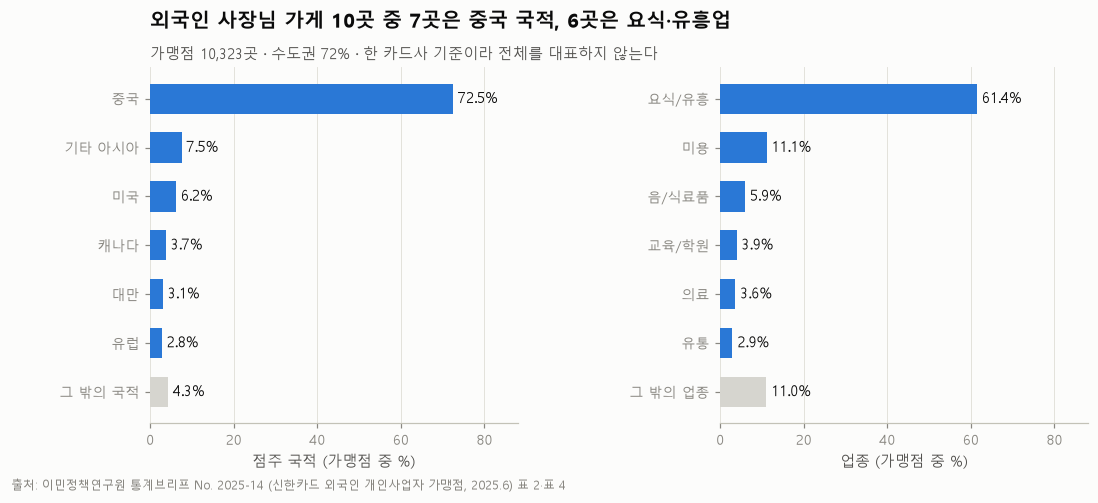

In [9]:
prof = M.owner_profile()
nat_p = pd.DataFrame(prof["nationality"]).set_index("name")
ind_p = pd.DataFrame(prof["industry"]).set_index("name")
nat_show = pd.concat([nat_p.share_pct.head(6), pd.Series({"그 밖의 국적": nat_p.share_pct.iloc[6:].sum()})])
ind_show = pd.concat([ind_p.drop(index="기타").share_pct.head(6),
                      pd.Series({"그 밖의 업종": ind_p.share_pct.sum() - ind_p.drop(index="기타").share_pct.head(6).sum()})])
print(nat_show.round(1).to_string()); print(ind_show.round(1).to_string())
print(f"수도권 {prof['capital_area_share_pct']:.1f}% · 영업 중 {prof['active']:,}곳 / 해지 {prof['closed']:,}곳({prof['closed_share_pct']:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(wspace=0.55))
for ax, ser, xl in ((axes[0], nat_show, "점주 국적 (가맹점 중 %)"), (axes[1], ind_show, "업종 (가맹점 중 %)")):
    d = ser.iloc[::-1]
    ax.barh(d.index, d.values, color=[C["neutral"] if i.startswith("그 밖") else SERIES[0] for i in d.index], height=0.62)
    for i, v in enumerate(d.values):
        ax.text(v + 1.2, i, f"{v:.1f}%", va="center", fontsize=9.5, color=C["ink"])
    ax.set_xlim(0, 88); ax.set_xlabel(xl); ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
axes[0].set_title("외국인 사장님 가게 10곳 중 7곳은 중국 국적, 6곳은 요식·유흥업")
V.subtitle(axes[0], f"가맹점 {prof['merchants']:,}곳 · 수도권 {prof['capital_area_share_pct']:.0f}% · 한 카드사 기준이라 전체를 대표하지 않는다")
V.finish(fig, FIG / "t12_owner_nationality_industry.png",
         "이민정책연구원 통계브리프 No. 2025-14 (신한카드 외국인 개인사업자 가맹점, 2025.6) 표 2·표 4")

### 1-5. 가게 규모와 업력 — 대부분 연매출 3억 원 이하이고, 4곳 중 3곳은 2020년 이후에 문을 열었다
대출 한도·대손율 가정을 잡을 때 직접 참고할 숫자다. 최근에 연 가게일수록 해지 비율이 높다.

row    3억 원 이하  3억~5억 원  5억~10억 원  10억~30억 원  30억 원 초과
col                                                   
의료       29.40    16.60     26.50      25.90      1.60
유통       58.70    14.20     22.10       5.00      0.00
요식/유흥    69.60    14.90     11.90       3.60      0.00
음/식료품    77.50    10.30      6.90       5.20      0.20
교육/학원    79.60     9.60      6.40       3.90      0.50
미용       97.90     1.60      0.30       0.30      0.00
전체       73.90    11.80     10.10       4.10      0.10


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (799 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


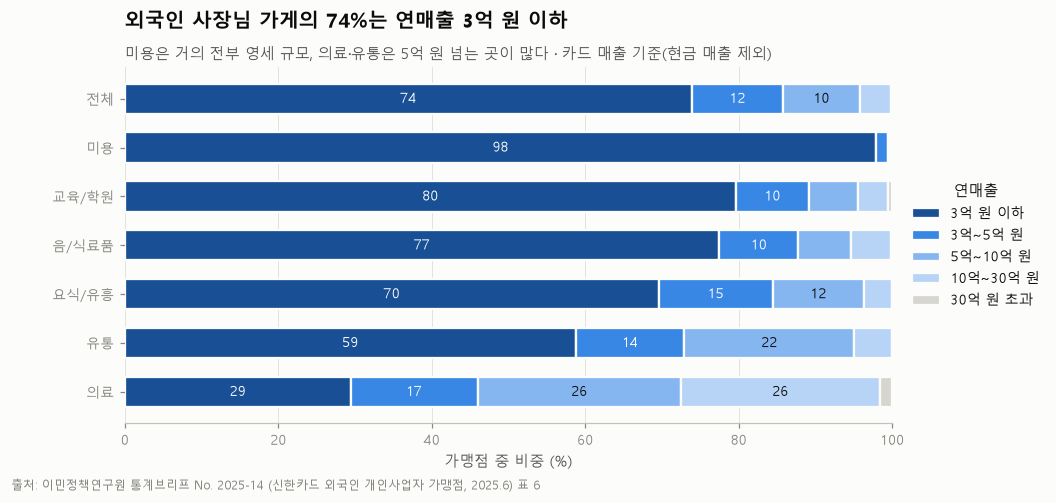

In [10]:
rev_b = L.load_mrtc_brief("revenue_industry").pivot(index="col", columns="row", values="value")
bands_o = ["3억 원 이하", "3억~5억 원", "5억~10억 원", "10억~30억 원", "30억 원 초과"]
rev_b = rev_b[bands_o]; rev_b.loc["전체"] = rev_b.sum()
rev_pct = rev_b.div(rev_b.sum(axis=1), axis=0) * 100
order_i = ["전체", "미용", "교육/학원", "음/식료품", "요식/유흥", "유통", "의료"]
rev_pct = rev_pct.loc[order_i[::-1]]
print(rev_pct.round(1).to_string())
fig, ax = plt.subplots(figsize=(9, 4.2))
left = np.zeros(len(rev_pct))
for bnd, col in zip(bands_o, [BLUE[10], BLUE[6], BLUE[3], BLUE[1], C["neutral"]]):
    ax.barh(rev_pct.index, rev_pct[bnd], left=left, color=col, height=0.62, label=bnd, edgecolor=C["surface"], linewidth=1.5)
    for yi, (l, v) in enumerate(zip(left, rev_pct[bnd])):
        if v >= 9:
            ax.text(l + v / 2, yi, f"{v:.0f}", ha="center", va="center", fontsize=9,
                    color="#ffffff" if col in (BLUE[10], BLUE[6]) else C["ink"])
    left += rev_pct[bnd].values
ax.set_xlim(0, 100); ax.set_xlabel("가맹점 중 비중 (%)"); ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="연매출")
ax.set_title(f"외국인 사장님 가게의 {rev_pct.loc['전체', '3억 원 이하']:.0f}%는 연매출 3억 원 이하")
V.subtitle(ax, "미용은 거의 전부 영세 규모, 의료·유통은 5억 원 넘는 곳이 많다 · 카드 매출 기준(현금 매출 제외)")
V.finish(fig, FIG / "t13_owner_revenue_bands.png",
         "이민정책연구원 통계브리프 No. 2025-14 (신한카드 외국인 개인사업자 가맹점, 2025.6) 표 6")

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (393 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


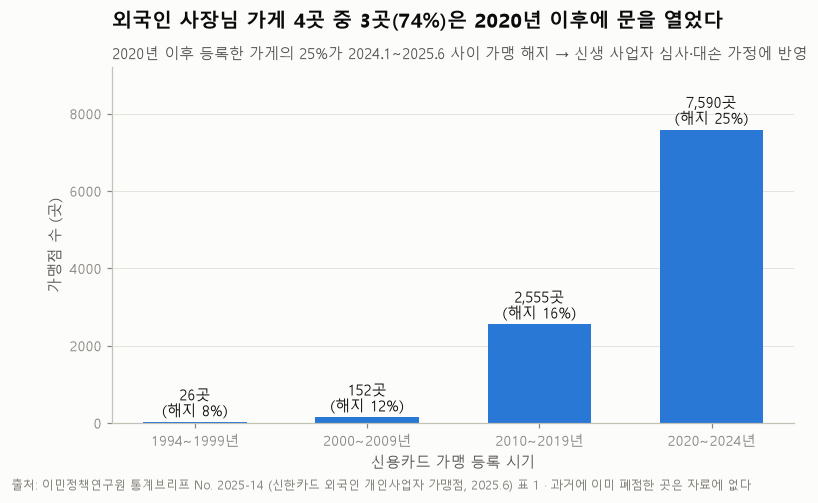

In [11]:
coh = pd.DataFrame(prof["cohorts"]).set_index("registered")
print(coh.round(1).to_string())
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(coh.index, coh["count"], color=SERIES[0], width=0.6)
for i, r in enumerate(coh.itertuples()):
    ax.text(i, r.count + 150, f"{r.count:,}곳\n(해지 {100 - r.still_active_pct:.0f}%)", ha="center", fontsize=9.5, color=C["ink"])
ax.set_ylim(0, 9200); ax.set_ylabel("가맹점 수 (곳)"); ax.set_xlabel("신용카드 가맹 등록 시기"); ax.grid(axis="x", visible=False)
ax.set_title(f"외국인 사장님 가게 4곳 중 3곳({coh.share_pct.iloc[-1]:.0f}%)은 2020년 이후에 문을 열었다")
V.subtitle(ax, f"2020년 이후 등록한 가게의 {100 - coh.still_active_pct.iloc[-1]:.0f}%가 2024.1~2025.6 사이 가맹 해지 → 신생 사업자 심사·대손 가정에 반영")
V.finish(fig, FIG / "t14_owner_cohorts.png",
         "이민정책연구원 통계브리프 No. 2025-14 (신한카드 외국인 개인사업자 가맹점, 2025.6) 표 1 · 과거에 이미 폐점한 곳은 자료에 없다")

In [12]:
# 교차 확인: 카드 가맹점 상위 10개 시군구와 법무부 '사업 가능 체류자격' 상위 10개 시군구가 얼마나 겹치나
card_top = [r["name"] for r in prof["top_regions"]]
moj_top = [r["label"] for r in M.top_regions(10)]
both = [x for x in card_top if x in moj_top]
print(f"두 자료 상위 10곳 중 {len(both)}곳이 같다: {', '.join(both)}")
print("카드 자료에만:", [x for x in card_top if x not in moj_top], "| 법무부 자료에만:", [x for x in moj_top if x not in card_top])

두 자료 상위 10곳 중 9곳이 같다: 경기 안산시, 경기 수원시, 서울 영등포구, 경기 시흥시, 경기 부천시, 경기 화성시, 경기 평택시, 서울 구로구, 인천 부평구
카드 자료에만: ['경기 성남시'] | 법무부 자료에만: ['서울 금천구']


---
## Q2. 돈이 되는 시장인가
### 2-1. 외국인이 내는 종합소득세: 인원도 1인당 세액도 늘고 있다

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


 year     filers  tax_eok  tax_per_filer_만원
 2019 125,836.00 5,101.00            405.37
 2020 129,059.00 5,712.00            442.59
 2021 154,132.00 5,878.00            381.36
 2022 184,717.00 8,659.00            468.77
 2023 221,078.00 7,098.00            321.06
 2024 253,050.00 7,846.00            310.06

2024 외국인 종소세 총 7,846억 원, 1인당 평균 310만 원
2025 한국발 개인송금 20.4조 원 (World Bank, 내국인 송금 포함 상한)


findfont: Font family 'Noto Sans CJK KR' not found.


... (513 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


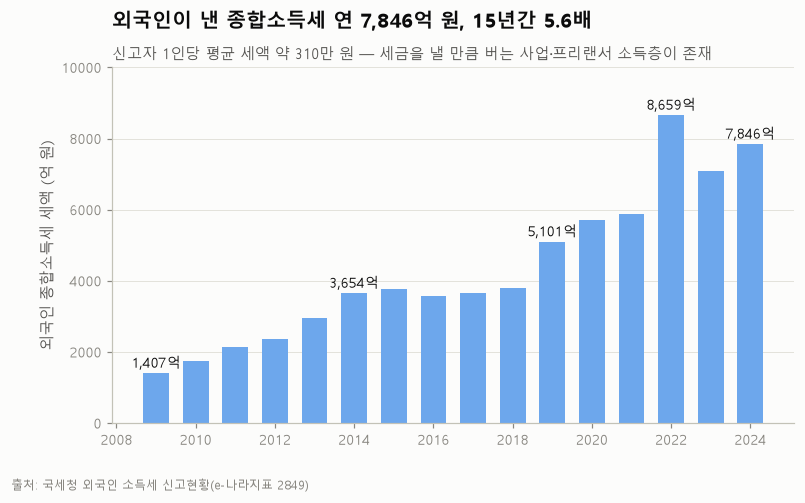

In [13]:
nts["tax_per_filer_만원"] = nts.tax_eok * 1e8 / nts.filers / 1e4
print(nts[["year", "filers", "tax_eok", "tax_per_filer_만원"]].tail(6).to_string(index=False))
rem25 = rem.set_index("year").krw_jo[2025]
print(f"\n2024 외국인 종소세 총 {nts.tax_eok.iloc[-1]:,.0f}억 원, 1인당 평균 {nts.tax_per_filer_만원.iloc[-1]:,.0f}만 원")
print(f"2025 한국발 개인송금 {rem25:.1f}조 원 (World Bank, 내국인 송금 포함 상한)")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(nts.year, nts.tax_eok, color=BLUE[4], width=0.65)
for y, v in zip(nts.year, nts.tax_eok):
    if y in (2009, 2014, 2019, 2022, 2024):
        ax.text(y, v + 150, f"{v:,.0f}억", ha="center", fontsize=9, color=C["ink"])
ax.set_ylabel("외국인 종합소득세 세액 (억 원)"); ax.grid(axis="x", visible=False); ax.set_ylim(0, 10000)
ax.set_title(f"외국인이 낸 종합소득세 연 {nts.tax_eok.iloc[-1]:,.0f}억 원, 15년간 {nts.tax_eok.iloc[-1]/nts.tax_eok.iloc[0]:.1f}배")
V.subtitle(ax, f"신고자 1인당 평균 세액 약 {nts.tax_per_filer_만원.iloc[-1]:,.0f}만 원 — 세금을 낼 만큼 버는 사업·프리랜서 소득층이 존재")
V.finish(fig, FIG / "t03_nts_tax_amount.png", "국세청 외국인 소득세 신고현황(e-나라지표 2849)")

### 2-2. 수익 시나리오 (보수 · 기준 · 낙관)
- **대출** = 타겟 수 × 침투율 × 평균 대출액 × (예대마진 − 대손비용률)
- **송금·정산 수수료** = 송금 외국인 수 × 침투율 × 1인 연 송금액(조사 분포) × 수수료율
- 타겟 수: 보수 = 2025 중심 추정, 기준·낙관 = 2028 전망

In [14]:
pop15 = sv("population", 2025).value.iloc[0] * 1e3
senders = pop15 * sv("remit_freq", 2025).set_index("category").loc["송금함", "value"] / 100
ra = sv("remit_amount", 2025).value.values / 100
mean_remit = float((ra * np.array(ASSUME["송금액 구간 대표값(만원)"])).sum()) * 1e4  # 원/년

scen = []
for k, name in enumerate(["보수", "기준", "낙관"]):
    n = emp_core[2025] if k == 0 else core_2028
    borrowers = n * ASSUME["침투율"][k]
    loan_book = borrowers * ASSUME["평균 대출액(만원)"][k] * 1e4
    loan_rev = loan_book * (ASSUME["예대마진"][k] - ASSUME["대손비용률"][k])
    users = senders * ASSUME["송금 침투율"][k]
    remit_rev = users * mean_remit * ASSUME["송금 수수료율"][k]
    scen.append(dict(시나리오=name, 타겟수=n, 대출고객=borrowers, 대출잔액_억=loan_book / 1e8,
                     대출수익_억=loan_rev / 1e8, 송금고객=users, 송금수익_억=remit_rev / 1e8,
                     합계_억=(loan_rev + remit_rev) / 1e8))
scen = pd.DataFrame(scen)
scen.to_csv(PROC / "revenue_scenarios.csv", index=False)
print(f"송금 외국인 {senders:,.0f}명, 1인 연 평균 송금 {mean_remit/1e4:,.0f}만 원")
print(scen.round(1).to_string(index=False))

송금 외국인 662,400명, 1인 연 평균 송금 1,473만 원
시나리오       타겟수     대출고객   대출잔액_억  대출수익_억      송금고객  송금수익_억   합계_억
  보수 55,900.00 1,677.00   335.40    5.00 19,872.00   14.60  19.70
  기준 73,212.70 3,660.60 1,098.20   27.50 33,120.00   48.80  76.20
  낙관 73,212.70 7,321.30 3,660.60  120.80 66,240.00  146.30 267.10


     1,000만  2,000만  3,000만  5,000만  7,000만
2%     3.70    7.30   11.00   18.30   25.60
3%     5.50   11.00   16.50   27.50   38.40
5%     9.20   18.30   27.50   45.80   64.10
7%    12.80   25.60   38.40   64.10   89.70
10%   18.30   36.60   54.90   91.50  128.10


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (1,202 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


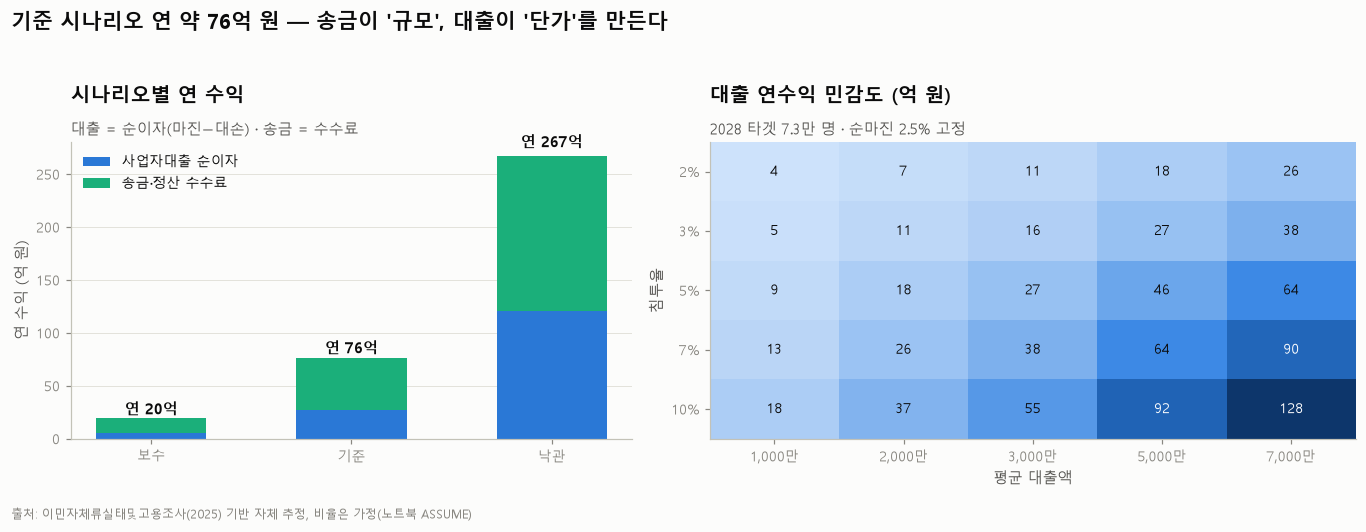

In [15]:
# 민감도: 기준 시나리오에서 침투율 × 평균 대출액만 바꿨을 때 대출 연수익(억 원)
pen = [0.02, 0.03, 0.05, 0.07, 0.10]; amt = [1000, 2000, 3000, 5000, 7000]
spread = ASSUME["예대마진"][1] - ASSUME["대손비용률"][1]
grid = pd.DataFrame([[core_2028 * p * a * 1e4 * spread / 1e8 for a in amt] for p in pen],
                    index=[f"{p:.0%}" for p in pen], columns=[f"{a:,}만" for a in amt])
print(grid.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax = axes[0]
xs = np.arange(len(scen))
ax.bar(xs, scen.대출수익_억, color=SERIES[0], width=0.55, label="사업자대출 순이자")
ax.bar(xs, scen.송금수익_억, bottom=scen.대출수익_억, color=SERIES[2], width=0.55, label="송금·정산 수수료")
for x, t in zip(xs, scen.합계_억):
    ax.text(x, t * 1.02 + 3, f"연 {t:,.0f}억", ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(xs); ax.set_xticklabels(scen.시나리오); ax.set_ylabel("연 수익 (억 원)")
ax.grid(axis="x", visible=False); ax.legend(loc="upper left")
ax.set_title("시나리오별 연 수익"); V.subtitle(ax, "대출 = 순이자(마진−대손) · 송금 = 수수료")
ax = axes[1]
im = ax.imshow(grid.values, cmap=V.SEQ, aspect="auto")
for i in range(len(pen)):
    for j in range(len(amt)):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=9,
                color="white" if v > grid.values.max() * 0.55 else C["ink"])
ax.set_xticks(range(len(amt))); ax.set_xticklabels(grid.columns); ax.set_yticks(range(len(pen))); ax.set_yticklabels(grid.index)
ax.set_xlabel("평균 대출액"); ax.set_ylabel("침투율"); ax.grid(False)
ax.set_title("대출 연수익 민감도 (억 원)"); V.subtitle(ax, f"2028 타겟 {core_2028/1e4:.1f}만 명 · 순마진 {spread:.1%} 고정")
fig.suptitle("기준 시나리오 연 약 {:,.0f}억 원 — 송금이 '규모', 대출이 '단가'를 만든다".format(scen.합계_억.iloc[1]),
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.04)
fig.tight_layout()
V.finish(fig, FIG / "t04_revenue_scenarios.png", "이민자체류실태및고용조사(2025) 기반 자체 추정, 비율은 가정(노트북 ASSUME)")

### 2-2b. 시장 퍼널 — 연 76억 원이 어디서 나오나
수익 시나리오(t04)와 **같은 계산**에서 나온 숫자로 대출·송금 퍼널을 그린다(보관함의 fig14는 다른 가정이라 숫자가 어긋났다).
단계마다 자료와 시점이 달라 단계 사이 비율을 전환율로 읽으면 안 된다. 마지막 단계의 침투율은 가정이다.

loan 예비 사장님 1,090,886명 사업 가능 체류자격 체류자 2026.9 0.0억
loan 외국인 사장님 73,213명 자영업자(고용주+1인) 전망 2028 0.0억
loan 대출 고객 3,661명 침투율 5% (가정) 2028 27.5억
remit 상주 외국인 1,692,300명 15세 이상 상주 외국인 2025.5 0.0억
remit 송금 외국인 662,400명 해외 송금을 하는 외국인 2025.5 0.0억
remit 송금 고객 33,120명 침투율 5% (가정) 2025.5 48.8억


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (471 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


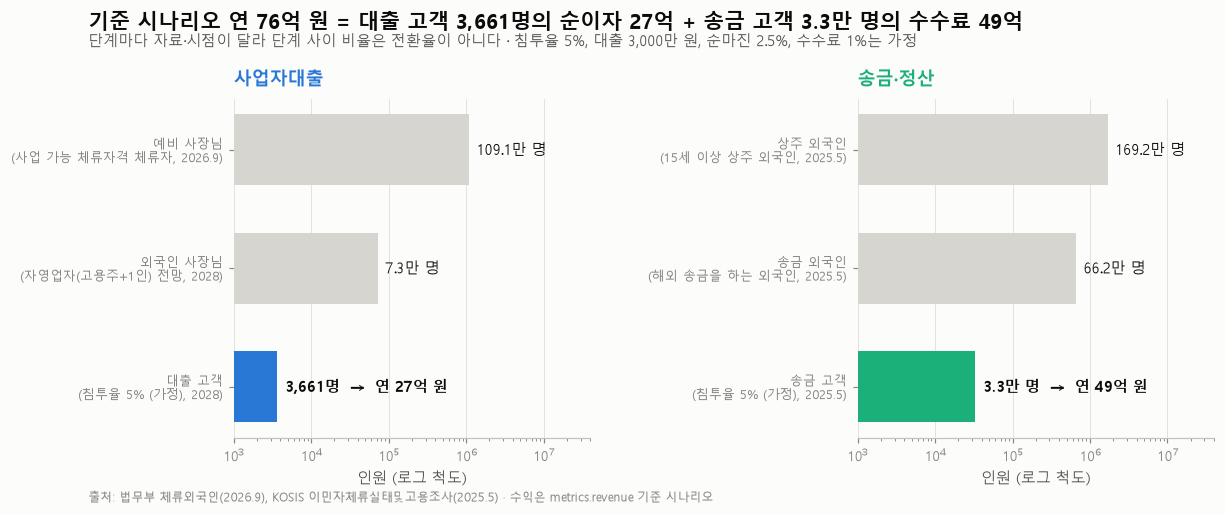

In [16]:
fun = M.market_funnel("기준")
for side in ("loan", "remit"):
    for s in fun[side]:
        print(side, s["stage"], f"{s['people']:,.0f}명", s["def"], s["as_of"], f"{s.get('revenue_won', 0)/1e8:,.1f}억")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw=dict(wspace=0.75))
for ax, side, col, name in ((axes[0], "loan", SERIES[0], "사업자대출"), (axes[1], "remit", SERIES[2], "송금·정산")):
    st = fun[side][::-1]
    ys = np.arange(len(st))
    ax.barh(ys, [s["people"] for s in st], color=[col] + [C["neutral"]] * (len(st) - 1), height=0.6)
    for yi, s in zip(ys, st):
        lab = f"{s['people']/1e4:,.1f}만 명" if s["people"] >= 1e4 else f"{s['people']:,.0f}명"
        if "revenue_won" in s:
            lab += f"  →  연 {s['revenue_won']/1e8:,.0f}억 원"
        ax.text(s["people"] * 1.25, yi, lab, va="center", fontsize=9.5, color=C["ink"],
                fontweight="bold" if "revenue_won" in s else "normal")
    ax.set_xscale("log"); ax.set_xlim(1e3, 4e7)
    ax.set_yticks(ys); ax.set_yticklabels([f"{s['stage']}\n({s['def']}, {s['as_of']})" for s in st], fontsize=8.5)
    ax.set_xlabel("인원 (로그 척도)"); ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
    ax.text(0, 1.04, name, transform=ax.transAxes, fontsize=11.5, fontweight="bold", color=col)
loan_c, remit_c = fun["loan"][-1], fun["remit"][-1]
fig.suptitle(f"기준 시나리오 연 {fun['total_revenue_won']/1e8:.0f}억 원 = 대출 고객 {loan_c['people']:,.0f}명의 순이자 "
             f"{loan_c['revenue_won']/1e8:.0f}억 + 송금 고객 {remit_c['people']/1e4:.1f}만 명의 수수료 {remit_c['revenue_won']/1e8:.0f}억",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.08)
fig.text(0.01, 1.0, "단계마다 자료·시점이 달라 단계 사이 비율은 전환율이 아니다 · 침투율 5%, 대출 3,000만 원, 순마진 2.5%, 수수료 1%는 가정",
         fontsize=9.5, color=C["ink2"])
V.finish(fig, FIG / "t17_market_funnel.png",
         "법무부 체류외국인(2026.9), KOSIS 이민자체류실태및고용조사(2025.5) · 수익은 metrics.revenue 기준 시나리오")

### 2-3. 송금 수요 추이 — 송금하는 외국인도, 매달 보내는 사람도, 고액 송금자도 늘었다 (2017~2025)
KOSIS 통계표(2년 주기)로 다섯 시점을 본다. 외국인 전체 기준이며 사장님만의 송금은 아니다.

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (639 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


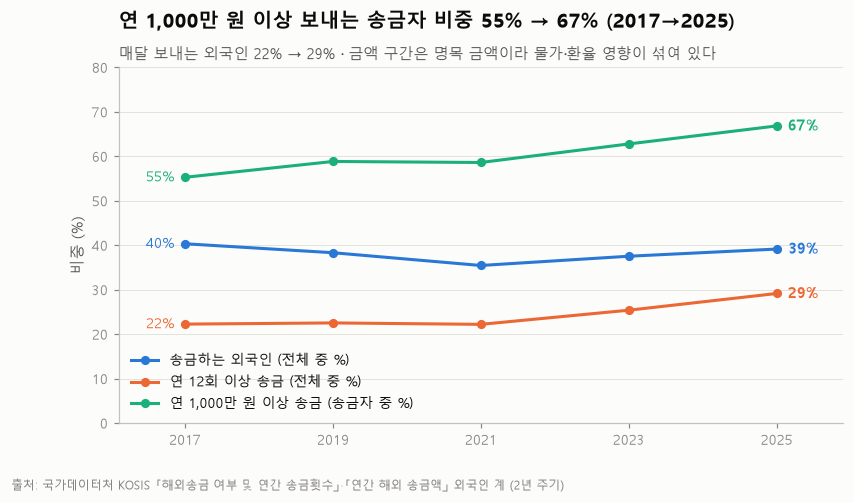

In [17]:
rf = sv("remit_freq").pivot(index="year", columns="category", values="value")
ram = sv("remit_amount").pivot(index="year", columns="category", values="value")
heavy = ram[["1000~1500만 원", "1500~2000만 원", "2000만 원 이상"]].sum(axis=1)
trend_remit = pd.DataFrame({"송금하는 외국인 (전체 중 %)": rf["송금함"], "연 12회 이상 송금 (전체 중 %)": rf["연 12회 이상"],
                            "연 1,000만 원 이상 송금 (송금자 중 %)": heavy})
print(trend_remit.round(1).to_string())
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for (lab, ser), col in zip(trend_remit.items(), [SERIES[0], SERIES[1], SERIES[2]]):
    ax.plot(ser.index, ser.values, color=col, marker="o", ms=5, label=lab)
    ax.text(ser.index[-1] + 0.15, ser.values[-1], f"{ser.values[-1]:.0f}%", va="center", fontsize=10, color=col, fontweight="bold")
    ax.text(ser.index[0] - 0.15, ser.values[0], f"{ser.values[0]:.0f}%", va="center", ha="right", fontsize=9, color=col)
ax.set_xticks(list(trend_remit.index)); ax.set_xlim(trend_remit.index[0] - 0.9, trend_remit.index[-1] + 0.9)
ax.set_ylim(0, 80); ax.set_ylabel("비중 (%)"); ax.grid(axis="x", visible=False)
ax.legend(loc="lower left", ncol=1, fontsize=9)
y0, y1 = int(trend_remit.index[0]), int(trend_remit.index[-1])
ax.set_title(f"연 1,000만 원 이상 보내는 송금자 비중 {heavy[y0]:.0f}% → {heavy[y1]:.0f}% ({y0}→{y1})")
V.subtitle(ax, f"매달 보내는 외국인 {rf['연 12회 이상'][y0]:.0f}% → {rf['연 12회 이상'][y1]:.0f}% · 금액 구간은 명목 금액이라 물가·환율 영향이 섞여 있다")
V.finish(fig, FIG / "t09_remittance_trend.png", "국가데이터처 KOSIS 「해외송금 여부 및 연간 송금횟수」·「연간 해외 송금액」 외국인 계 (2년 주기)")

### 2-4. 고객이 얻는 이익 — 송금 수수료 1%는 누구보다 싼가
송금 외국인 1인의 연 송금액(조사 분포)과 1년 송금 횟수로 **1인당 연 송금 비용**을 비교한다.
- 시중은행 건당 수수료(1만·3만 원)는 블로그 출처라 신뢰도가 낮고 **환율 마진이 빠져 있다**.
- World Bank 총비용(5.36~5.90%)은 환율 마진까지 넣은 값이지만 200달러 송금 기준이라 큰 금액에는 과대하다.
- 12회 이상 송금은 12회로 두었다. 실제 횟수가 더 많으면 1회 금액은 작아지고 건당 수수료 비율은 커진다.

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (451 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


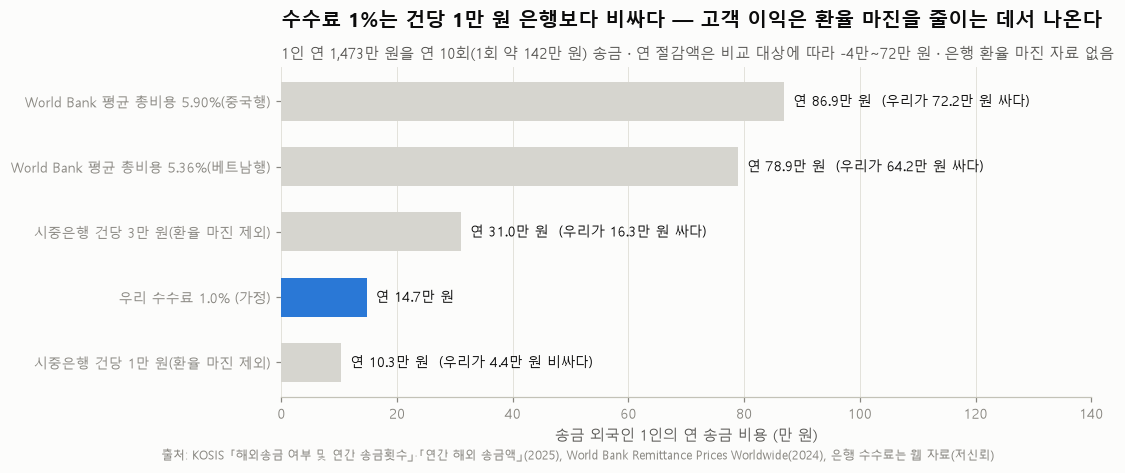

In [18]:
sv_ = M.remittance_savings()
print(f"1인 연 송금 {sv_['annual_remittance_won']/1e4:,.0f}만 원 · 연 {sv_['transfers_per_year']:.1f}회 · 1회 {sv_['per_transfer_won']/1e4:,.0f}만 원")
alts = pd.DataFrame(sv_["alternatives"])
print(alts.round(0).to_string(index=False))
bars = pd.concat([pd.DataFrame([{"label": f"우리 수수료 {sv_['our_fee_pct']:.1f}% (가정)", "annual_cost_won": sv_["our_annual_cost_won"],
                                 "saving_won": 0.0}]), alts[["label", "annual_cost_won", "saving_won"]]]).sort_values("annual_cost_won")
fig, ax = plt.subplots(figsize=(9.5, 3.9))
ys = np.arange(len(bars))
ax.barh(ys, bars.annual_cost_won / 1e4, color=[SERIES[0] if l.startswith("우리") else C["neutral"] for l in bars.label], height=0.6)
for yi, (_, r) in zip(ys, bars.iterrows()):
    txt = f"연 {r.annual_cost_won/1e4:,.1f}만 원"
    if not r.label.startswith("우리"):
        txt += f"  (우리가 {abs(r.saving_won)/1e4:,.1f}만 원 {'싸다' if r.saving_won > 0 else '비싸다'})"
    ax.text(r.annual_cost_won / 1e4 + 1.5, yi, txt, va="center", fontsize=9, color=C["ink"])
ax.set_yticks(ys); ax.set_yticklabels(bars.label, fontsize=9)
ax.set_xlim(0, 140); ax.set_xlabel("송금 외국인 1인의 연 송금 비용 (만 원)"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.set_title("수수료 1%는 건당 1만 원 은행보다 비싸다 — 고객 이익은 환율 마진을 줄이는 데서 나온다")
V.subtitle(ax, f"1인 연 {sv_['annual_remittance_won']/1e4:,.0f}만 원을 연 {sv_['transfers_per_year']:.0f}회(1회 약 {sv_['per_transfer_won']/1e4:,.0f}만 원) 송금 · "
               f"연 절감액은 비교 대상에 따라 {sv_['saving_range_won'][0]/1e4:,.0f}만~{sv_['saving_range_won'][1]/1e4:,.0f}만 원 · 은행 환율 마진 자료 없음")
V.finish(fig, FIG / "t19_remittance_savings.png",
         "KOSIS 「해외송금 여부 및 연간 송금횟수」·「연간 해외 송금액」(2025), World Bank Remittance Prices Worldwide(2024), 은행 수수료는 웹 자료(저신뢰)")

---
## Q3. 상환능력이 있는가 — DSR 40% 통과 비율
3,000만 원을 연 6%·5년 원리금균등으로 빌리면 월 상환액은 약 58만 원이다. DSR 40%를 넘지 않으려면 월소득이 약 145만 원 이상이어야 한다.
체류자격별 **소득자** 월소득 분포(2025 조사)에서 그 기준을 넘는 비율을 구간 내 선형보간으로 추정한다.

⚠ 조사의 소득은 자영업자만이 아니라 해당 체류자격 전체(임금근로 포함)라서 *체류자격의 소득 체력*을 보는 대리지표다.

In [19]:
r, n = ASSUME["대출금리(연)"] / 12, ASSUME["대출기간(월)"]
def pmt(principal):
    return principal * r / (1 - (1 + r) ** -n)
BINS = [("inc_lt100", 0, 100), ("inc_100_200", 100, 200), ("inc_200_300", 200, 300), ("inc_300p", 300, None)]

def share_above(row, need):
    earners = sum(row[c] for c, *_ in BINS)
    above = 0.0
    for c, lo, hi in BINS:
        if hi is None:
            above += row[c] if need <= lo else row[c] * 0.5   # 300만+ 구간은 기준이 300 초과면 절반만 인정(보수)
        elif need <= lo:
            above += row[c]
        elif need < hi:
            above += row[c] * (hi - need) / (hi - lo)
    return above / earners * 100

loans = [2000, 3000, 5000]
need = {a: pmt(a * 1e4) / ASSUME["DSR 한도"] / 1e4 for a in loans}  # 만원/월
for a in loans:
    print(f"대출 {a:,}만 원 → 월 상환 {pmt(a*1e4)/1e4:,.1f}만 원 → 필요 월소득 {need[a]:,.0f}만 원")
dsr = visa[["visa_label", "grp", "inc_none", "utility_miss", "saving_share", "stay_10yp", "own_home"]].copy()
for a in loans:
    dsr[f"DSR통과_{a}"] = visa.apply(lambda row: share_above(row, need[a]), axis=1)
dsr = dsr.sort_values("DSR통과_3000", ascending=False)
dsr.to_csv(PROC / "repayment_dsr_by_visa.csv", index=False)
print(dsr.round(1).to_string(index=False))

w = visa.set_index("visa_label").pop_k * (100 - visa.set_index("visa_label").inc_none) / 100   # 소득자 수 가중
g = dsr.set_index("visa_label").join(w.rename("earners_k")).groupby("grp").apply(
    lambda d: pd.Series({f"DSR통과_{a}": np.average(d[f"DSR통과_{a}"], weights=d.earners_k) for a in loans}
                        | {"공과금미납": np.average(d.utility_miss, weights=d.earners_k)}))
print("\n집단별(소득자 수 가중):"); print(g.round(1))

대출 2,000만 원 → 월 상환 38.7만 원 → 필요 월소득 97만 원
대출 3,000만 원 → 월 상환 58.0만 원 → 필요 월소득 145만 원
대출 5,000만 원 → 월 상환 96.7만 원 → 필요 월소득 242만 원
   visa_label    grp  inc_none  utility_miss  saving_share  stay_10yp  own_home  DSR통과_2000  DSR통과_3000  DSR통과_5000
   비전문취업(E-9) 취업·학업형      0.00          0.50         11.60       0.30      0.00      100.00       99.50       70.50
전문인력(E-1~E-7) 취업·학업형      0.40          1.10         15.70      25.30      0.50       99.80       98.40       77.70
      영주(F-5)  가족정착형     20.70          2.20         20.80      88.80     39.80       97.60       93.90       77.50
    재외동포(F-4)  가족정착형     32.10          3.90         18.40      60.00     20.20       96.10       91.10       68.80
    방문취업(H-2) 취업·학업형     20.00          4.70         18.60      45.80      5.80       97.20       90.60       65.30
           기타     기타     43.50          5.00         14.80      14.80      9.30       94.20       86.20       56.40
    결혼이민(F-6)  가족정착형     38.30          4.20         18.60  

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (544 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


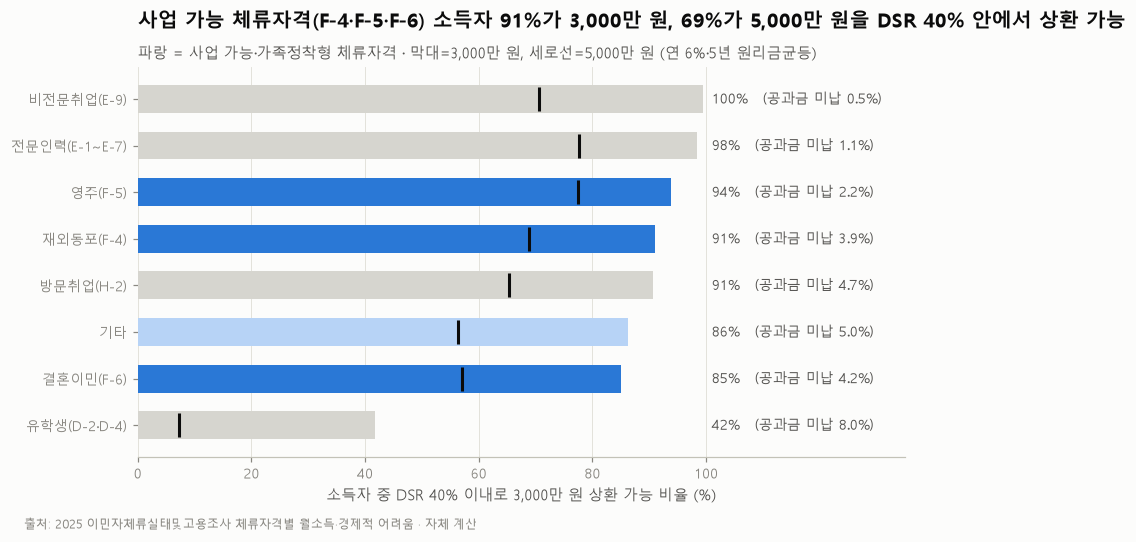

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.6))
d = dsr.iloc[::-1]
cols = [SERIES[0] if gp == "가족정착형" else (C["neutral"] if gp != "기타" else BLUE[1]) for gp in d.grp]
ax.barh(d.visa_label, d.DSR통과_3000, color=cols, height=0.6)
ax.scatter(d.DSR통과_5000, range(len(d)), marker="|", s=260, color=C["ink"], zorder=3)
for i, (v, um) in enumerate(zip(d.DSR통과_3000, d.utility_miss)):
    ax.text(101, i, f"{v:.0f}%   (공과금 미납 {um:.1f}%)", va="center", fontsize=9, color=C["ink2"])
ax.set_xlim(0, 135); ax.set_xticks(range(0, 101, 20)); ax.set_xlabel("소득자 중 DSR 40% 이내로 3,000만 원 상환 가능 비율 (%)")
ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
fam, fam5 = g.loc["가족정착형", "DSR통과_3000"], g.loc["가족정착형", "DSR통과_5000"]
ax.set_title(f"사업 가능 체류자격(F-4·F-5·F-6) 소득자 {fam:.0f}%가 3,000만 원, {fam5:.0f}%가 5,000만 원을 DSR 40% 안에서 상환 가능")
V.subtitle(ax, "파랑 = 사업 가능·가족정착형 체류자격 · 막대=3,000만 원, 세로선=5,000만 원 (연 6%·5년 원리금균등)")
V.finish(fig, FIG / "t05_repayment_dsr.png", "2025 이민자체류실태및고용조사 체류자격별 월소득·경제적 어려움 · 자체 계산")

### 3-2. 소득 추이 — 월 300만 원 이상 버는 외국인 비중이 꾸준히 늘었다 (2017~2025)
소득이 있는 사람만 분모로 잡았다. 임금근로자가 대부분이라 사장님 소득을 직접 보여 주지는 않는다.

category  100만 원 미만  100~200만 원  200~300만 원  300만 원 이상
year                                                  
2017           8.80       39.00       42.00      10.30
2019          11.60       28.10       45.00      15.30
2021           8.10       25.20       46.20      20.50
2023           5.60       13.10       46.60      34.70
2025           5.00       11.70       46.20      37.10


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (705 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


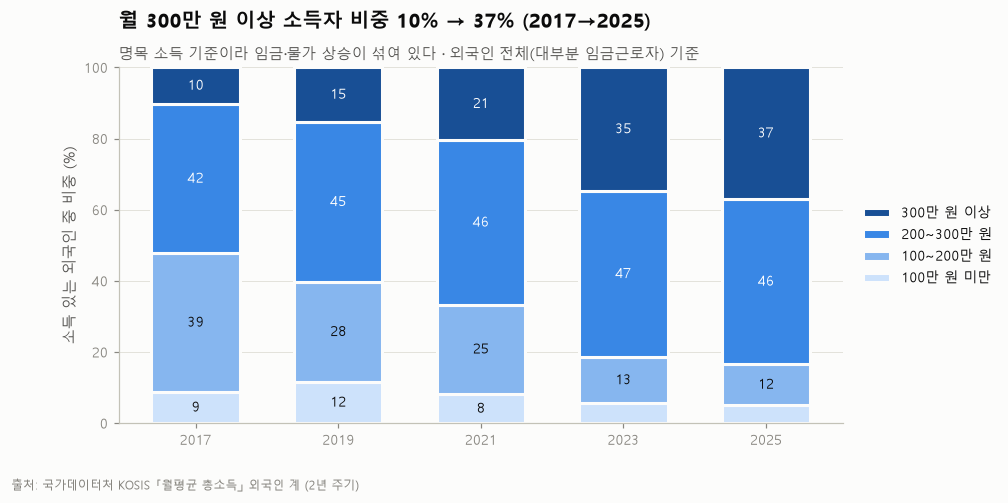

In [21]:
inc = sv("income").pivot(index="year", columns="category", values="value")
earn = inc.drop(columns="없음"); earn = earn.div(earn.sum(axis=1), axis=0) * 100
order_inc = ["100만 원 미만", "100~200만 원", "200~300만 원", "300만 원 이상"]
print(earn[order_inc].round(1).to_string())
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bottom = np.zeros(len(earn)); xpos = np.arange(len(earn))
for cat, col in zip(order_inc, [BLUE[0], BLUE[3], BLUE[6], BLUE[10]]):
    ax.bar(xpos, earn[cat], bottom=bottom, color=col, width=0.62, label=cat, edgecolor=C["surface"], linewidth=2)
    for xi, b, v in zip(xpos, bottom, earn[cat]):
        if v >= 7:
            ax.text(xi, b + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=9,
                    color="#ffffff" if col in (BLUE[6], BLUE[10]) else C["ink"])
    bottom += earn[cat].values
ax.set_xticks(xpos); ax.set_xticklabels(earn.index); ax.set_ylim(0, 100); ax.set_ylabel("소득 있는 외국인 중 비중 (%)")
ax.grid(axis="x", visible=False)
hd, lb = ax.get_legend_handles_labels()
ax.legend(hd[::-1], lb[::-1], loc="center left", bbox_to_anchor=(1.01, 0.5))
y0, y1 = int(earn.index[0]), int(earn.index[-1])
ax.set_title(f"월 300만 원 이상 소득자 비중 {earn['300만 원 이상'][y0]:.0f}% → {earn['300만 원 이상'][y1]:.0f}% ({y0}→{y1})")
V.subtitle(ax, "명목 소득 기준이라 임금·물가 상승이 섞여 있다 · 외국인 전체(대부분 임금근로자) 기준")
V.finish(fig, FIG / "t10_income_trend.png", "국가데이터처 KOSIS 「월평균 총소득」 외국인 계 (2년 주기)")

### 3-3. 타겟 가중 연체율 — 대손비용률 가정(기준 1.0%)은 맞나
우리 타겟의 구성(카드 가맹점의 매출 구간·업력·업종, 외국인 자영업자의 1인 사업자 비중)으로
국내 개인사업자 연체율(국가데이터처 「개인사업자 부채」, 2024년 말, 내국인 포함)을 가중 평균한다.
- 사업자대출(전 금융권)과 은행 대출 두 가지로 계산한다. 은행 대출은 담보·보증과 우량 차주 비중이 높아 훨씬 낮다.
- 연체율은 "지금 밀린 대출의 비중"이고 대손비용률은 "한 해 떼일 것으로 잡는 비용"이다. 가까운 참고값으로만 쓴다.
- 매출 구간은 카드 매출과 전체 연매출의 정의가 달라 거칠게 맞췄다. 3억 원 이하 안의 분포를 몰라 범위로 낸다.

   관점   낮음  가운데   높음  은행만(가운데)  비은행만(가운데)                                                          메모
매출 구간 0.82 1.22 2.31      0.18       1.73 카드 매출 기준 구간을 KOSIS 전체 연매출 구간에 맞췄다. 3억 원 이하 안의 분포를 몰라 범위로 낸다
   업력 1.39 1.40 1.41      0.23       2.11     가맹 등록 시기로 업력을 추정했다. 2020년 이후 개업의 '3년 미만' 비중을 50~70%로 가정
직원 유무 1.09 1.09 1.09      0.19       1.55                     외국인 자영업자 중 고용원 없는 비중 67.4% (KOSIS 2025)
   업종 1.20 1.20 1.20      0.19       2.03                  카드사 업종을 표준산업분류에 근사 대응(요식/유흥 → 숙박 및 음식점업 등)
전국 개인사업자 사업자대출 연체율 추이: {2017: 0.22, 2018: 0.24, 2019: 0.37, 2020: 0.37, 2021: 0.3, 2022: 0.37, 2023: 0.74, 2024: 1.16}


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (385 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


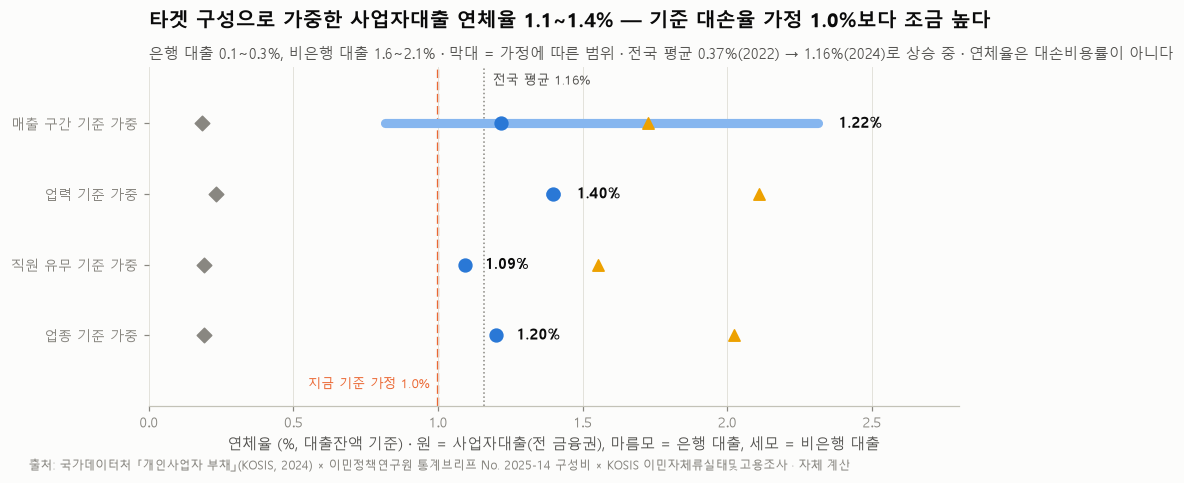

In [22]:
twd = M.target_weighted_delinquency()
rows_t = pd.DataFrame([{"관점": k, "낮음": v["biz"]["low"], "가운데": v["biz"]["mid"], "높음": v["biz"]["high"],
                        "은행만(가운데)": v["bank"]["mid"], "비은행만(가운데)": v["nonbank"]["mid"], "메모": v["note"]} for k, v in twd["dims"].items()])
print(rows_t.round(2).to_string(index=False))
print("전국 개인사업자 사업자대출 연체율 추이:", {k: round(v, 2) for k, v in twd["national_trend_biz"].items()})
fig, ax = plt.subplots(figsize=(9.5, 4.0))
order_t = rows_t.iloc[::-1].reset_index(drop=True)
for yi, r in order_t.iterrows():
    ax.plot([r["낮음"], r["높음"]], [yi, yi], color=BLUE[3], lw=6, solid_capstyle="round", zorder=1)
    ax.scatter(r["가운데"], yi, s=70, color=SERIES[0], zorder=3)
    ax.scatter(r["은행만(가운데)"], yi, s=45, color=C["muted"], marker="D", zorder=3)
    ax.scatter(r["비은행만(가운데)"], yi, s=55, color=SERIES[3], marker="^", zorder=3)
    ax.text(max(r["높음"], r["가운데"]) + 0.07, yi, f"{r['가운데']:.2f}%", va="center", fontsize=9.5, color=C["ink"], fontweight="bold")
nat_b = twd["national"]["biz"]
ax.axvline(nat_b, color=C["muted"], lw=1, ls=":", zorder=0)
ax.text(nat_b + 0.03, len(order_t) - 0.45, f"전국 평균 {nat_b:.2f}%", ha="left", fontsize=8.5, color=C["ink2"])
ax.axvline(1.0, color=SERIES[1], lw=1.5, ls="--", zorder=0)
ax.text(0.97, -0.75, "지금 기준 가정 1.0%", ha="right", fontsize=8.5, color=SERIES[1])
ax.set_yticks(range(len(order_t))); ax.set_yticklabels(order_t["관점"] + " 기준 가중")
ax.set_ylim(-1.0, len(order_t) - 0.2); ax.set_xlim(0, 2.8)
ax.set_xlabel("연체율 (%, 대출잔액 기준) · 원 = 사업자대출(전 금융권), 마름모 = 은행 대출, 세모 = 비은행 대출"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
mr = twd["summary_biz"]["mid_range"]
ax.set_title(f"타겟 구성으로 가중한 사업자대출 연체율 {mr[0]:.1f}~{mr[1]:.1f}% — 기준 대손율 가정 1.0%보다 조금 높다")
tr = twd["national_trend_biz"]
V.subtitle(ax, f"은행 대출 0.1~0.3%, 비은행 대출 1.6~2.1% · 막대 = 가정에 따른 범위 · 전국 평균 {tr[2022]:.2f}%(2022) → "
               f"{tr[max(tr)]:.2f}%({max(tr)})로 상승 중 · 연체율은 대손비용률이 아니다")
V.finish(fig, FIG / "t15_target_weighted_delinquency.png",
         "국가데이터처 「개인사업자 부채」(KOSIS, 2024) × 이민정책연구원 통계브리프 No. 2025-14 구성비 × KOSIS 이민자체류실태및고용조사 · 자체 계산")

---
## Q4. 거주민이 될 사람들인가 — 상관관계
### 4-1. 시군구 단위: 사업 가능 외국인 비중이 높은 지역일수록 오래 머물고 국적을 딴다
- X: 시군구 체류외국인 중 사업 가능 체류자격 비중(법무부 2026.9)
- Y: 10년 이상 체류 비중, 국적취득자 비중, 장기정착(10년+ 또는 귀화) 비중(행안부 2024.11)
- 통제: 외국인 규모(log) — 외국인이 많은 대도시 효과 제거. OLS, HC3 강건표준오차, 표준화 β

In [23]:
b = pd.read_csv(PROC / "region_business_eligible.csv")
c = pd.read_csv(PROC / "region_children_settlement.csv")
# 행정구역 이름 맞추기 (광주·전남 통합 / 세종 / 인천 2013 경계)
GJ = {"광산구", "남구", "동구", "북구", "서구"}
b["key"] = b.label.where(~b.label.str.startswith("전남 "),
                         b.label.map(lambda s: ("광주 " if s.split(" ", 1)[1] in GJ else "전라 ") + s.split(" ", 1)[1]))
b.loc[b.key == "세종 세종특별자치시", "key"] = "세종 세종시"
c["key"] = c.label.replace({"인천 미추홀구": "인천 남구", "인천 중구": "인천 중구·동구", "인천 동구": "인천 중구·동구"})
cnt = ["fr_total", "naturalized", "children", "stay_10y", "stay_known"]
c = c.groupby("key", as_index=False)[cnt].sum()
c["stay10"] = c.stay_10y / c.stay_known * 100
c["natur"] = c.naturalized / c.fr_total * 100
c["settle_long"] = (c.stay_10y + c.naturalized) / (c.stay_known + c.naturalized) * 100
c["log_fr"] = np.log10(c.fr_total)
m = b[["key", "biz", "총합계"]].merge(c, on="key")
m["biz_share"] = m.biz / m["총합계"] * 100
m = m[m["총합계"] >= 1000]  # 외국인 1천 명 미만 시군구는 비율이 불안정 → 제외
print(f"분석 시군구 n = {len(m)}")

YS = {"stay10": "10년 이상 체류(%)", "natur": "국적취득자(%)", "settle_long": "장기정착: 10년+ 또는 귀화(%)"}
z = lambda s: (s - s.mean()) / s.std()
rows = []
for y, lab in YS.items():
    rho = stats.spearmanr(m.biz_share, m[y])
    X = sm.add_constant(pd.DataFrame({"biz_share": z(m.biz_share), "log_fr": z(m.log_fr)}))
    fit = sm.OLS(z(m[y]), X).fit(cov_type="HC3")
    lo, hi = fit.conf_int().loc["biz_share"]
    rows.append(dict(Y=lab, spearman_rho=rho.statistic, rho_p=rho.pvalue, beta=fit.params["biz_share"],
                     lo=lo, hi=hi, p=fit.pvalues["biz_share"], R2=fit.rsquared, n=len(m)))
corr4 = pd.DataFrame(rows)
corr4.to_csv(PROC / "settlement_corr_region.csv", index=False)
print(corr4.round(3).to_string(index=False))

분석 시군구 n = 208
                  Y  spearman_rho  rho_p  beta   lo   hi    p   R2   n
       10년 이상 체류(%)          0.89   0.00  1.02 0.97 1.07 0.00 0.89 208
           국적취득자(%)          0.49   0.00  0.83 0.71 0.96 0.00 0.53 208
장기정착: 10년+ 또는 귀화(%)          0.79   0.00  1.04 0.99 1.10 0.00 0.83 208


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (1,099 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


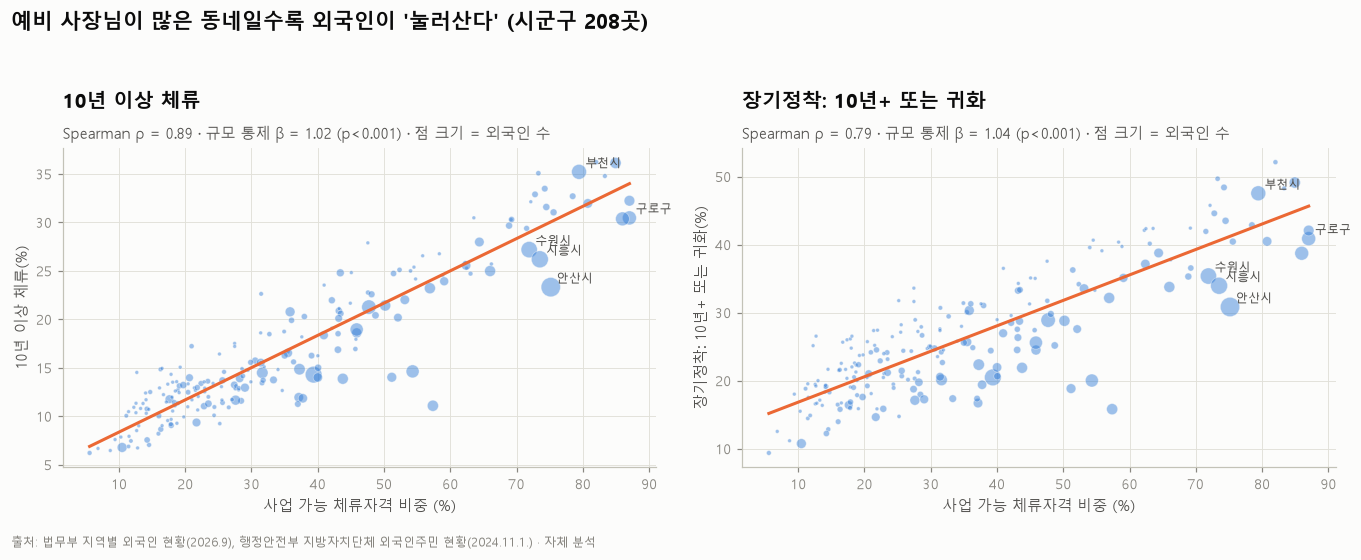

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
for ax, y in zip(axes, ["stay10", "settle_long"]):
    sz = np.clip(m["총합계"] / 600, 6, 160)
    ax.scatter(m.biz_share, m[y], s=sz, color=SERIES[0], alpha=0.45, edgecolor=C["surface"], linewidth=0.5)
    k, b0 = np.polyfit(m.biz_share, m[y], 1)
    xx = np.linspace(m.biz_share.min(), m.biz_share.max(), 50)
    ax.plot(xx, k * xx + b0, color=SERIES[1], linewidth=2)
    for _, rr in m.nlargest(5, "biz").iterrows():
        ax.annotate(rr.key.split(" ", 1)[1], (rr.biz_share, rr[y]), xytext=(4, 3), textcoords="offset points",
                    fontsize=8, color=C["ink2"])
    rr = corr4.set_index("Y").loc[YS[y]]
    ax.set_xlabel("사업 가능 체류자격 비중 (%)"); ax.set_ylabel(YS[y])
    ax.set_title(YS[y].split("(")[0].strip())
    V.subtitle(ax, f"Spearman ρ = {rr.spearman_rho:.2f} · 규모 통제 β = {rr.beta:.2f} (p<0.001) · 점 크기 = 외국인 수")
fig.suptitle(f"예비 사장님이 많은 동네일수록 외국인이 '눌러산다' (시군구 {len(m)}곳)", x=0.01, ha="left",
             fontsize=14, fontweight="bold", y=1.05)
fig.tight_layout()
V.finish(fig, FIG / "t06_settlement_corr_region.png",
         "법무부 지역별 외국인 현황(2026.9), 행정안전부 지방자치단체 외국인주민 현황(2024.11.1.) · 자체 분석")

### 4-2. 체류자격 단위: 정착 지표와 상환능력 지표가 같이 움직이나
8개 체류자격(n=8)이라 통계적 검정력은 약하고 **방향 확인용**이다. 집단 간 비율차 검정은 `children_hypothesis` A1 참조(전부 p<0.001).

         10년+ 체류  자기 집  월 300만+  저축 비중  공과금 미납
10년+ 체류     1.00  0.86     0.76   0.90   -0.10
자기 집        0.86  1.00     0.43   0.79    0.12
월 300만+     0.76  0.43     1.00   0.75   -0.60
저축 비중       0.90  0.79     0.75   1.00   -0.18
공과금 미납     -0.10  0.12    -0.60  -0.18    1.00
                 지표  가족정착형(%)  취업·학업형(%)  차이(%p)    p
       체류 10년 이상(%)     64.90       8.04   56.86 0.00
        계속 체류 희망(%)     96.51      85.13   11.38 0.00
         자기 집 거주(%)     29.60       0.72   28.89 0.00
월소득 300만+ (소득자 중 %)     47.41      30.43   16.99 0.00
   공과금 미납 경험(%) ↓좋음      3.56       3.48    0.07 0.85


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (537 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


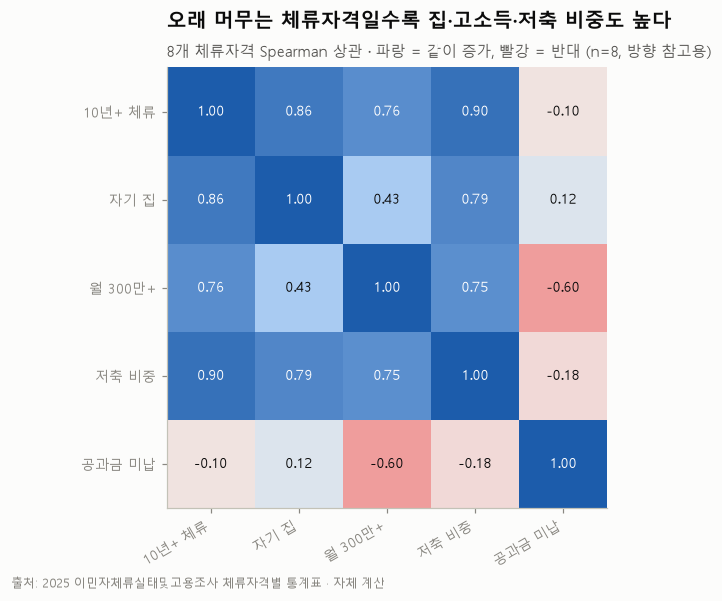

In [25]:
vi = visa.set_index("visa_label")
vi["DSR통과_3000"] = dsr.set_index("visa_label")["DSR통과_3000"]
# DSR 통과율은 임금 폭이 좁은 E-9가 높게 나와 정착 지표와 성격이 달라 제외
cols = {"stay_10yp": "10년+ 체류", "own_home": "자기 집", "inc_300p_earn": "월 300만+",
        "saving_share": "저축 비중", "utility_miss": "공과금 미납"}
cm = vi[list(cols)].rename(columns=cols).corr("spearman")
print(cm.round(2))
a1 = pd.read_csv(PROC / "test_A1_visa_groups.csv")
print(a1[["지표", "가족정착형(%)", "취업·학업형(%)", "차이(%p)", "p"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.8, 5.2))
im = ax.imshow(cm.values, cmap=V.DIV, vmin=-1, vmax=1)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(cm.values[i, j]) > 0.7 else C["ink"])
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=30, ha="right")
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.index); ax.grid(False)
ax.set_title("오래 머무는 체류자격일수록 집·고소득·저축 비중도 높다")
V.subtitle(ax, "8개 체류자격 Spearman 상관 · 파랑 = 같이 증가, 빨강 = 반대 (n=8, 방향 참고용)")
V.finish(fig, FIG / "t07_visa_corr_matrix.png", "2025 이민자체류실태및고용조사 체류자격별 통계표 · 자체 계산")

### 4-3. 정착 추이 — 사업 가능 자격(F-4·F-5·F-6)은 10년 넘게 머문 사람이 해마다 늘었다 (2013~2025)
같은 사람을 따라간 자료가 아니라 해마다 다른 표본이다. 체류자격을 바꾼 사람(예: H-2 → F-4)이 섞여 구성 효과가 있다.

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (457 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


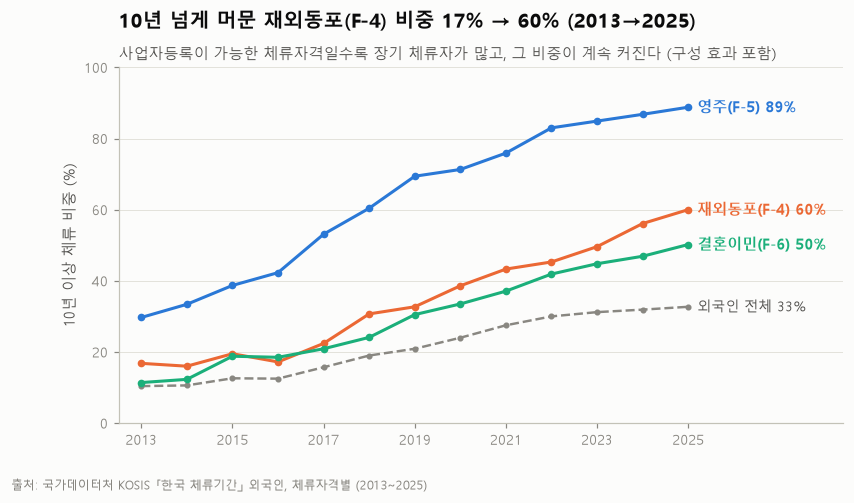

In [26]:
st = L.kosis_wide("DT_2FK003R", by="visa")["T700"].unstack("visa")     # 10년 이상 체류 비중(%)
tot = L.kosis_wide("DT_2FK003R")["T700"]
lines = [("F5", "영주(F-5)", SERIES[0]), ("F4", "재외동포(F-4)", SERIES[1]), ("F6", "결혼이민(F-6)", SERIES[2])]
print(pd.concat([st[[k for k, *_ in lines]], tot.rename("외국인 전체")], axis=1).round(1).to_string())
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(tot.index, tot.values, color=C["muted"], lw=1.6, ls="--", marker="o", ms=3, label="외국인 전체")
ax.text(tot.index[-1] + 0.2, tot.values[-1], f"외국인 전체 {tot.values[-1]:.0f}%", va="center", fontsize=9, color=C["ink2"])
for k, lab, col in lines:
    ser = st[k].dropna()
    ax.plot(ser.index, ser.values, color=col, marker="o", ms=4, label=lab)
    ax.text(ser.index[-1] + 0.2, ser.values[-1], f"{lab} {ser.values[-1]:.0f}%", va="center", fontsize=9.5,
            color=col, fontweight="bold")
ax.set_xticks(list(range(int(tot.index[0]), int(tot.index[-1]) + 1, 2))); ax.set_xlim(tot.index[0] - 0.5, tot.index[-1] + 3.4)
ax.set_ylim(0, 100); ax.set_ylabel("10년 이상 체류 비중 (%)"); ax.grid(axis="x", visible=False)
y0, y1 = int(st["F4"].dropna().index[0]), int(tot.index[-1])
ax.set_title(f"10년 넘게 머문 재외동포(F-4) 비중 {st['F4'][y0]:.0f}% → {st['F4'][y1]:.0f}% ({y0}→{y1})")
V.subtitle(ax, "사업자등록이 가능한 체류자격일수록 장기 체류자가 많고, 그 비중이 계속 커진다 (구성 효과 포함)")
V.finish(fig, FIG / "t11_stay10y_trend.png", "국가데이터처 KOSIS 「한국 체류기간」 외국인, 체류자격별 (2013~2025)")

### 4-4. 정착 흐름 — 사업 가능 자격의 상당수는 다른 체류자격에서 넘어왔다
체류자격을 바꾼 적이 있는 외국인의 비율을 **지금의 체류자격별로** 본다(KOSIS 2012~2025).
해마다 다른 표본이라 같은 사람을 따라간 값이 아니다. t11(장기 체류 비중 상승)의 구성 효과를 설명하는 근거이기도 하다.

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (559 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


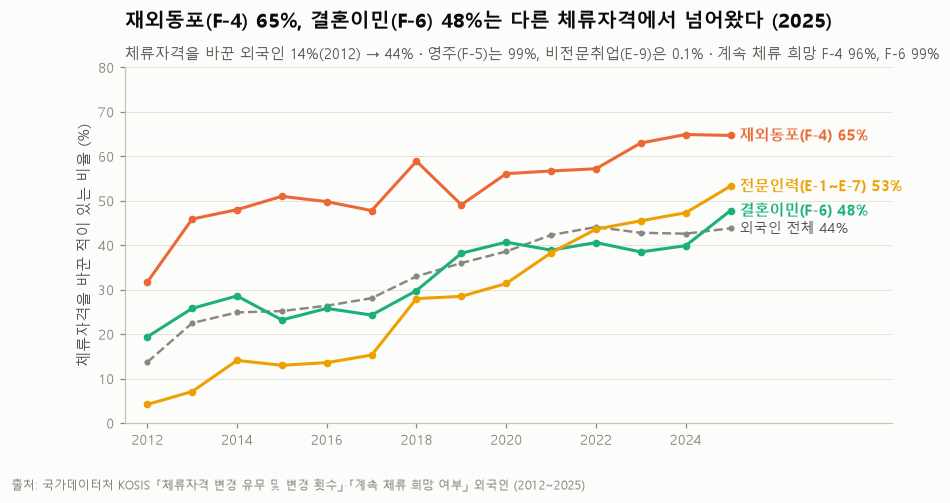

In [27]:
vc = M.visa_change_trend()
tot_vc = pd.Series(vc["total"]); byv = pd.DataFrame(vc["by_visa"])
print(pd.concat([byv[["F4", "F5", "F6", "E1_7", "E9"]], tot_vc.rename("전체")], axis=1).round(1).to_string())
print("계속 체류 희망(최근):", {k: round(v, 1) for k, v in vc["wish_stay_latest"].items()})
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(tot_vc.index, tot_vc.values, color=C["muted"], lw=1.6, ls="--", marker="o", ms=3)
ax.text(tot_vc.index[-1] + 0.2, tot_vc.values[-1], f"외국인 전체 {tot_vc.values[-1]:.0f}%", va="center", fontsize=9, color=C["ink2"])
for k, lab, col in (("F4", "재외동포(F-4)", SERIES[1]), ("F6", "결혼이민(F-6)", SERIES[2]), ("E1_7", "전문인력(E-1~E-7)", SERIES[3])):
    s_ = byv[k].dropna()
    ax.plot(s_.index, s_.values, color=col, marker="o", ms=4)
    ax.text(s_.index[-1] + 0.2, s_.values[-1], f"{lab} {s_.values[-1]:.0f}%", va="center", fontsize=9.5, color=col, fontweight="bold")
ax.set_xticks(list(range(int(tot_vc.index[0]), int(tot_vc.index[-1]) + 1, 2)))
ax.set_xlim(tot_vc.index[0] - 0.5, tot_vc.index[-1] + 3.6); ax.set_ylim(0, 80)
ax.set_ylabel("체류자격을 바꾼 적이 있는 비율 (%)"); ax.grid(axis="x", visible=False)
y1 = vc["latest_year"]
ax.set_title(f"재외동포(F-4) {byv['F4'][y1]:.0f}%, 결혼이민(F-6) {byv['F6'][y1]:.0f}%는 다른 체류자격에서 넘어왔다 ({y1})")
V.subtitle(ax, f"체류자격을 바꾼 외국인 {tot_vc.iloc[0]:.0f}%({int(tot_vc.index[0])}) → {tot_vc.iloc[-1]:.0f}% · 영주(F-5)는 {byv['F5'][y1]:.0f}%, "
               f"비전문취업(E-9)은 {byv['E9'][y1]:.1f}% · 계속 체류 희망 F-4 {vc['wish_stay_latest']['F4']:.0f}%, F-6 {vc['wish_stay_latest']['F6']:.0f}%")
V.finish(fig, FIG / "t20_visa_change_flow.png", "국가데이터처 KOSIS 「체류자격 변경 유무 및 변경 횟수」·「계속 체류 희망 여부」 외국인 (2012~2025)")

---
## 팀 최종 초안 근거 — 비자 스텝업 마이너스 통장 · 선배 귀화인 커뮤니티 P2P
팀 최종 초안(`data/raw/team/proposal_draft_final.pdf`)은 송금 대신 두 대출 상품을 제안한다. 아래는 초안의 주장마다 붙일 근거다.
초안의 금리·한도·수수료는 초안 스스로 "가정"이라고 밝힌 예시값이고(`metrics.DRAFT_ASSUME`), 이용률·대출 기간은 우리가 둔 가정이다.

### D-1. 정착 사다리에 오르는 사람 — KIIP 참여, 영주, 귀화
비자 스텝업의 마일스톤(KIIP 단계 → 영주·귀화 신청 → 국적 취득)을 실제로 밟는 사람이 얼마나 되는지 본다.
외국인 전체 숫자이고 자영업자만 따로 세지는 않는다.

2015   25,795.00
2016   30,515.00
2017   41,500.00
2018   50,639.00
2019   56,535.00
2020   36,620.00
2021   43,552.00
2022   42,163.00
2023   58,028.00
2024   70,949.00
2025   90,180.00
2015   10,924.00
2016   10,108.00
2017   10,086.00
2018   11,556.00
2019    9,914.00
2020   13,885.00
2021   10,895.00
2022   10,248.00
2023   10,346.00
2024   11,008.00
2025   11,344.00
2020-12   160,947.00
2021-12   168,118.00
2022-12   176,107.00
2023-12   185,441.00
2024-12   202,968.00
2025-12   221,021.00
2026-09   233,668.00
영주권자 국적 취득 계획: {2019: 59.1, 2022: 60.0, 2024: 62.1} · KIIP 평균 학습기간(개월): {2018: 10.3, 2020: 10.0, 2022: 10.5, 2023: 8.9, 2024: 8.9, 2025: 8.9}
최근 5년 귀화자: {'year': 2025, 'population_k': 51.5, 'employed_k': 34.3, 'self_employed_k': 4.6, 'self_emp_share_of_employed_pct': 13.411078717201166, 'foreign_self_emp_share_of_employed_pct': 5.039213918687461}


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (1,201 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


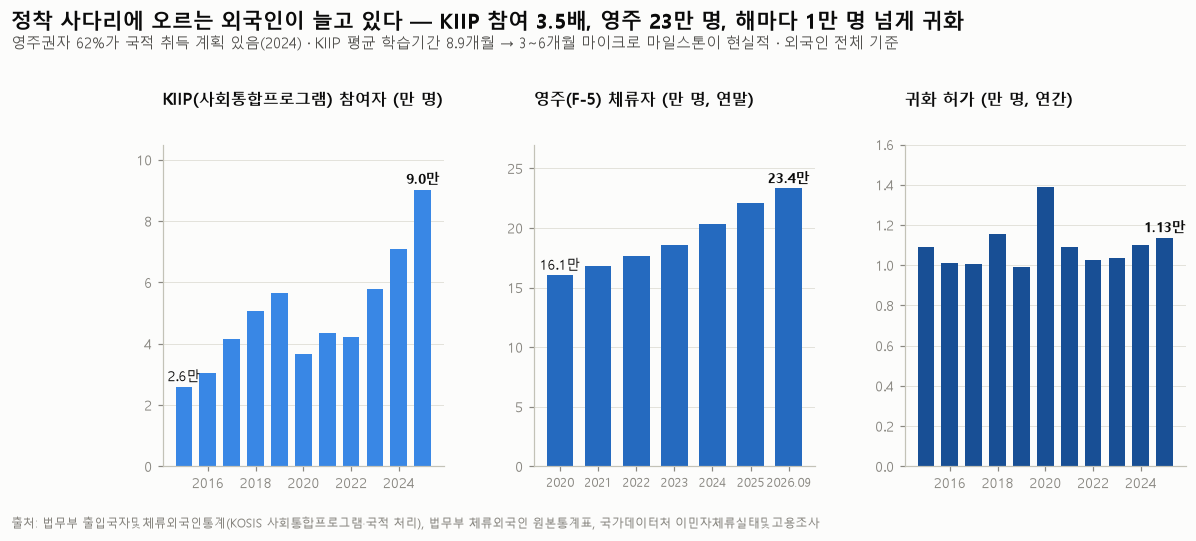

In [28]:
sp = M.settlement_pipeline()
kp = pd.Series(sp["kiip_participants"]); nz = pd.Series(sp["naturalized_per_year"]).loc[2015:]
f5 = pd.Series(sp["f5_stock"])
print(kp.loc[2015:].to_string()); print(nz.to_string()); print(f5.to_string())
print("영주권자 국적 취득 계획:", sp["f5_plan_naturalize_pct"], "· KIIP 평균 학습기간(개월):", sp["kiip_avg_learning_months"])
print("최근 5년 귀화자:", sp["recent_naturalized"])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw=dict(wspace=0.32))
k15 = kp.loc[2015:]
axes[0].bar(k15.index, k15.values / 1e4, color=BLUE[6], width=0.7)
axes[0].text(k15.index[0], k15.iloc[0] / 1e4 + 0.2, f"{k15.iloc[0]/1e4:.1f}만", ha="center", fontsize=9)
axes[0].text(k15.index[-1], k15.iloc[-1] / 1e4 + 0.2, f"{k15.iloc[-1]/1e4:.1f}만", ha="center", fontsize=9, fontweight="bold")
axes[0].set_title("KIIP(사회통합프로그램) 참여자 (만 명)", fontsize=10.5)
f5y = f5.copy(); f5y.index = [i[:4] if i.endswith("-12") else i.replace("-", ".") for i in f5y.index]
axes[1].bar(range(len(f5y)), f5y.values / 1e4, color=BLUE[8], width=0.7)
axes[1].set_xticks(range(len(f5y))); axes[1].set_xticklabels(f5y.index, fontsize=8, rotation=0)
for i in (0, len(f5y) - 1):
    axes[1].text(i, f5y.iloc[i] / 1e4 + 0.4, f"{f5y.iloc[i]/1e4:.1f}만", ha="center", fontsize=9, fontweight="bold" if i else "normal")
axes[1].set_title("영주(F-5) 체류자 (만 명, 연말)", fontsize=10.5)
axes[2].bar(nz.index, nz.values / 1e4, color=BLUE[10], width=0.7)
axes[2].text(nz.index[-1], nz.iloc[-1] / 1e4 + 0.03, f"{nz.iloc[-1]/1e4:.2f}만", ha="center", fontsize=9, fontweight="bold")
axes[2].set_title("귀화 허가 (만 명, 연간)", fontsize=10.5)
for ax in axes:
    ax.grid(axis="x", visible=False)
axes[0].set_ylim(0, 10.5); axes[1].set_ylim(0, 27); axes[2].set_ylim(0, 1.6)
fig.suptitle(f"정착 사다리에 오르는 외국인이 늘고 있다 — KIIP 참여 {k15.iloc[-1]/k15.iloc[0]:.1f}배, 영주 {f5.iloc[-1]/1e4:.0f}만 명, 해마다 1만 명 넘게 귀화",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.2)
fig.text(0.01, 1.11, f"영주권자 {sp['f5_plan_naturalize_pct'][max(sp['f5_plan_naturalize_pct'])]:.0f}%가 국적 취득 계획 있음({max(sp['f5_plan_naturalize_pct'])}) · "
         f"KIIP 평균 학습기간 {sp['kiip_avg_learning_months'][max(sp['kiip_avg_learning_months'])]:.1f}개월 → 3~6개월 마이크로 마일스톤이 현실적 · 외국인 전체 기준",
         fontsize=9.5, color=C["ink2"])
V.finish(fig, FIG / "t21_settlement_ladder.png",
         "법무부 출입국자및체류외국인통계(KOSIS 사회통합프로그램·국적 처리), 법무부 체류외국인 원본통계표, 국가데이터처 이민자체류실태및고용조사")

### D-2. 비자 스텝업의 단계별 금리 — 고객은 얼마를 아끼고, DSR은 걸림돌인가
한도 1,500만 원, 평균 이용률 70%(우리 가정), 한도대출을 5년 분할로 보고 DSR 40%를 계산한다(우리 가정).
DSR 통과 비율은 체류자격별 **임금소득 포함** 소득분포로 계산한 대리 추정이다.

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (605 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


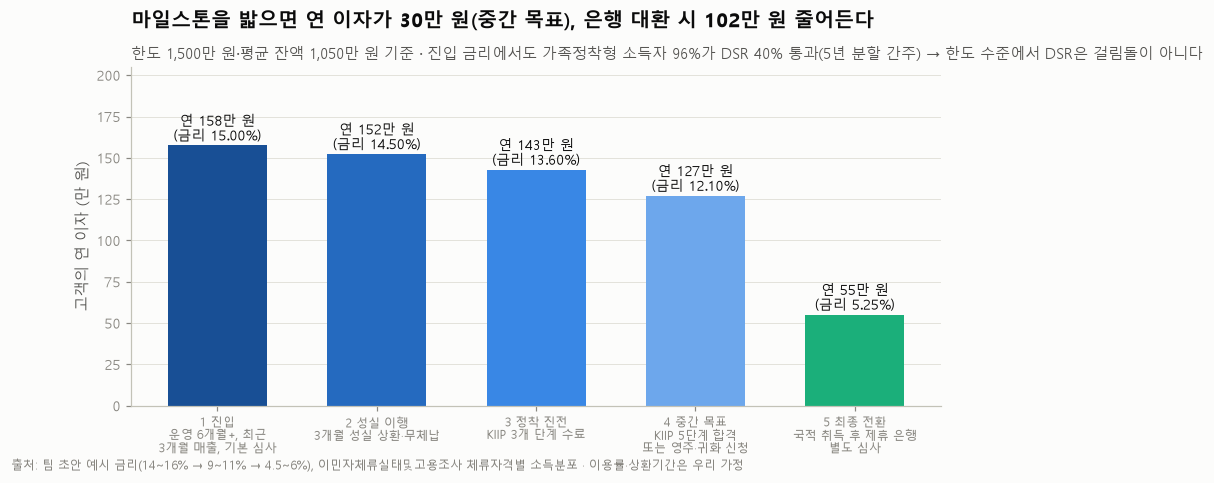

In [29]:
rp = M.draft_repayment()
st_ = pd.DataFrame(rp["stages"])
st_["가족정착형 DSR 통과(%)"] = st_.pass_by_group.map(lambda d: d["가족정착형"])
print(st_[["stage", "rate", "monthly_payment_won", "required_monthly_income_won", "가족정착형 DSR 통과(%)", "annual_interest_won"]].round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(9.5, 4.0))
xs = np.arange(len(st_))
ax.bar(xs, st_.annual_interest_won / 1e4, color=[BLUE[10], BLUE[8], BLUE[6], BLUE[4], SERIES[2]], width=0.62)
for xi, r in st_.iterrows():
    ax.text(xi, r.annual_interest_won / 1e4 + 3, f"연 {r.annual_interest_won/1e4:,.0f}만 원\n(금리 {r.rate*100:.2f}%)", ha="center", fontsize=9)
import textwrap
ax.set_xticks(xs); ax.set_xticklabels([r.stage + "\n" + "\n".join(textwrap.wrap(r.condition, 13)) for r in st_.itertuples()], fontsize=8)
ax.set_ylim(0, 205); ax.set_ylabel("고객의 연 이자 (만 원)"); ax.grid(axis="x", visible=False)
ax.set_title(f"마일스톤을 밟으면 연 이자가 {rp['saving_to_mid_won']/1e4:.0f}만 원(중간 목표), 은행 대환 시 {rp['saving_to_final_won']/1e4:.0f}만 원 줄어든다")
V.subtitle(ax, f"한도 1,500만 원·평균 잔액 {rp['avg_balance_won']/1e4:,.0f}만 원 기준 · 진입 금리에서도 가족정착형 소득자 "
               f"{st_['가족정착형 DSR 통과(%)'].iloc[0]:.0f}%가 DSR 40% 통과(5년 분할 간주) → 한도 수준에서 DSR은 걸림돌이 아니다")
V.finish(fig, FIG / "t22_stepup_interest_path.png",
         "팀 초안 예시 금리(14~16% → 9~11% → 4.5~6%), 이민자체류실태및고용조사 체류자격별 소득분포 · 이용률·상환기간은 우리 가정")

### D-3. 초안 금리와 시장 금리 — 역선택(한계 ②)을 숫자로 확인
초안의 진입 금리 14~16%를 고객이 실제로 고를 수 있는 다른 대출과 비교한다. 대부분 보도에서 옮긴 값이다(`assumption_evidence.csv`).

                   label  rate    as_of            grade
인터넷은행 3사 일반신용대출 평균금리(신규)  5.58  2026-05               보도
      예금은행 일반신용대출 금리(신규)  6.49  2026-09            공식 통계
 인터넷은행 신용점수 600점 이하 평균금리  7.89  2026-05               보도
     온투업 6개사 개인신용대출 평균금리 11.72     2026   보도(온투협회 자료 인용)
      카드론 평균금리(8개 전업카드사) 13.54  2026-05 보도(여신금융협회 공시 인용)
        저축은행 개인신용대출 평균금리 14.67  2026-09   보도(온투협회 자료 인용)
  카드론 평균금리(신용점수 700점 이하) 17.45  2026-07 보도(여신금융협회 공시 인용)
                 법정 최고금리 20.00 2021-07~               법령


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (583 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


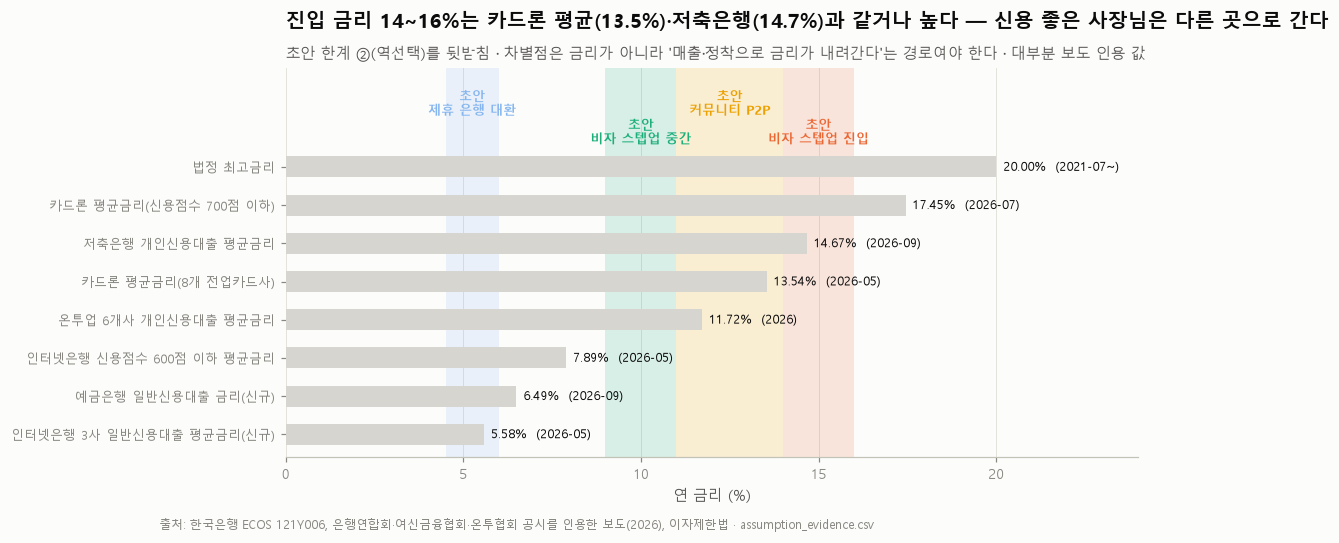

In [30]:
rb = M.rate_benchmarks()
bm = pd.DataFrame(rb["benchmarks"]); dr = pd.DataFrame(rb["draft"])
print(bm[["label", "rate", "as_of", "grade"]].to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 4.6))
bands = [(SERIES[1], "초안 비자 스텝업 진입"), (SERIES[3], "초안 커뮤니티 P2P"), (SERIES[2], "초안 비자 스텝업 중간"), (BLUE[3], "초안 제휴 은행 대환")]
for k_, (col, lab) in enumerate(bands):
    r = dr.set_index("label").loc[lab]
    ax.axvspan(r.low, r.high, color=col, alpha=0.16, lw=0)
    ax.text((r.low + r.high) / 2, len(bm) - 0.45 + (0.75 if k_ % 2 else 0), lab.replace("초안 ", "초안\n"), ha="center", va="bottom", fontsize=8.5, color=col, fontweight="bold")
ys = np.arange(len(bm))
ax.barh(ys, bm.rate, color=C["neutral"], height=0.55)
for yi, r in zip(ys, bm.itertuples()):
    ax.text(r.rate + 0.2, yi, f"{r.rate:.2f}%  ({r.as_of})", va="center", fontsize=8.5, color=C["ink"])
ax.set_yticks(ys); ax.set_yticklabels(bm.label, fontsize=8.5)
ax.set_xlim(0, 24); ax.set_ylim(-0.6, len(bm) + 1.6); ax.set_xlabel("연 금리 (%)")
ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
ax.set_title("진입 금리 14~16%는 카드론 평균(13.5%)·저축은행(14.7%)과 같거나 높다 — 신용 좋은 사장님은 다른 곳으로 간다")
V.subtitle(ax, "초안 한계 ②(역선택)를 뒷받침 · 차별점은 금리가 아니라 '매출·정착으로 금리가 내려간다'는 경로여야 한다 · 대부분 보도 인용 값")
V.finish(fig, FIG / "t23_rate_benchmarks.png",
         "한국은행 ECOS 121Y006, 은행연합회·여신금융협회·온투협회 공시를 인용한 보도(2026), 이자제한법 · assumption_evidence.csv")

### D-4. 선배 귀화인 멘토는 어디에 있나 — 초안의 거점(안산·대림·수원·이태원) 점검
행안부 「외국인주민 현황」(2024.11)의 시군구별 **국적 취득 5년 이상** 주민을 멘토 후보 모집단으로 본다.
예비 사장님(법무부 2026.9) 100명당 멘토 후보 수를 함께 적는다. 멘토 후보 수 전국 추정은 거친 값이다.

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (797 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


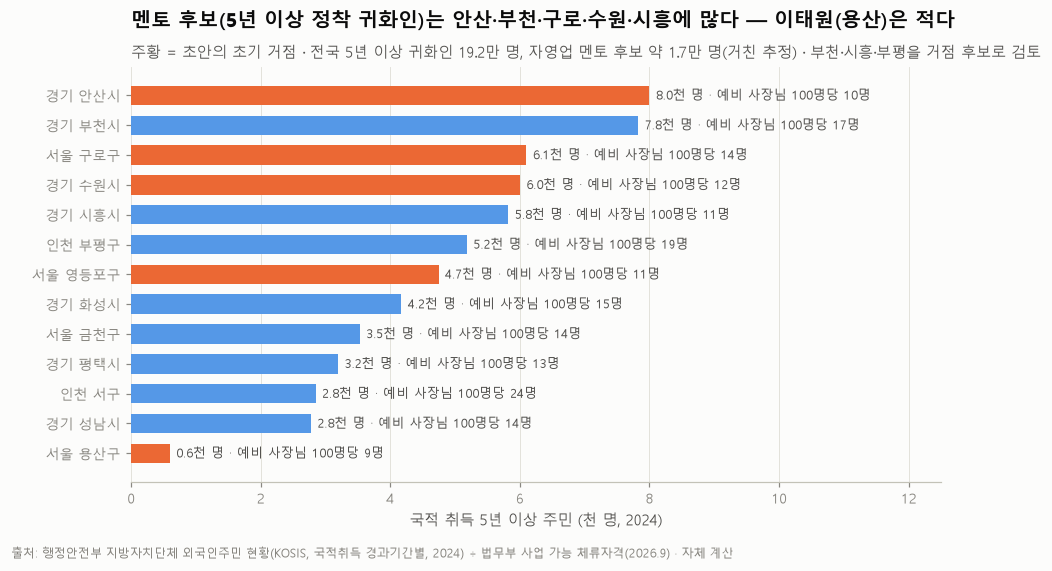

In [31]:
mp = M.mentor_pool(12)
mt = pd.DataFrame(mp["top"]).set_index("label")
print(f"국적 취득자 {mp['naturalized_total']:,.0f}명 중 5년 이상 {mp['naturalized_5y_plus']:,.0f}명 · 멘토 후보 추정 {mp['mentor_candidates_est']:,.0f}명 ({mp['est_note']})")
print(mt.round(1).to_string()); print(pd.DataFrame(mp["draft_hubs"]).round(1).to_string(index=False))
hub_labels = {h["label"] for h in mp["draft_hubs"]}
show = mt.copy()
for h in mp["draft_hubs"]:
    if h["label"] not in show.index and h.get("naturalized_5y_plus") is not None:
        show.loc[h["label"]] = {k: h[k] for k in ("naturalized_5y_plus", "naturalized_all", "prospective", "per_100_prospective")}
show = show.sort_values("naturalized_5y_plus")
fig, ax = plt.subplots(figsize=(9.5, 4.9))
ax.barh(show.index, show.naturalized_5y_plus / 1e3, color=[SERIES[1] if i in hub_labels else BLUE[5] for i in show.index], height=0.65)
for i, (k, r) in enumerate(show.iterrows()):
    ax.text(r.naturalized_5y_plus / 1e3 + 0.1, i, f"{r.naturalized_5y_plus/1e3:,.1f}천 명 · 예비 사장님 100명당 {r.per_100_prospective:.0f}명",
            va="center", fontsize=8.5, color=C["ink2"])
ax.set_xlim(0, 12.5); ax.set_xlabel("국적 취득 5년 이상 주민 (천 명, 2024)"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.set_title("멘토 후보(5년 이상 정착 귀화인)는 안산·부천·구로·수원·시흥에 많다 — 이태원(용산)은 적다")
V.subtitle(ax, f"주황 = 초안의 초기 거점 · 전국 5년 이상 귀화인 {mp['naturalized_5y_plus']/1e4:.1f}만 명, 자영업 멘토 후보 약 {mp['mentor_candidates_est']/1e4:.1f}만 명(거친 추정) · "
               "부천·시흥·부평을 거점 후보로 검토")
V.finish(fig, FIG / "t24_mentor_pool.png",
         "행정안전부 지방자치단체 외국인주민 현황(KOSIS, 국적취득 경과기간별, 2024) ÷ 법무부 사업 가능 체류자격(2026.9) · 자체 계산")

### D-5. 커뮤니티 P2P의 단위경제성 — 멘토는 손해를 보지 않나 (한계 ③ 닭과 달걀)
2,000만 원 대출(12개월 원리금균등, 우리 가정), 금리 12.5%, 중개 수수료 3%, 관리 수수료 12%(초안 예시).
멘토 200만 원(10%) 후순위가 손실을 먼저 진다. 손실률 대리값은 연체율이다(연체율 ≠ 손실률).

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


... (447 outputs left out)

findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


findfont: Font family 'Noto Sans CJK KR' not found.


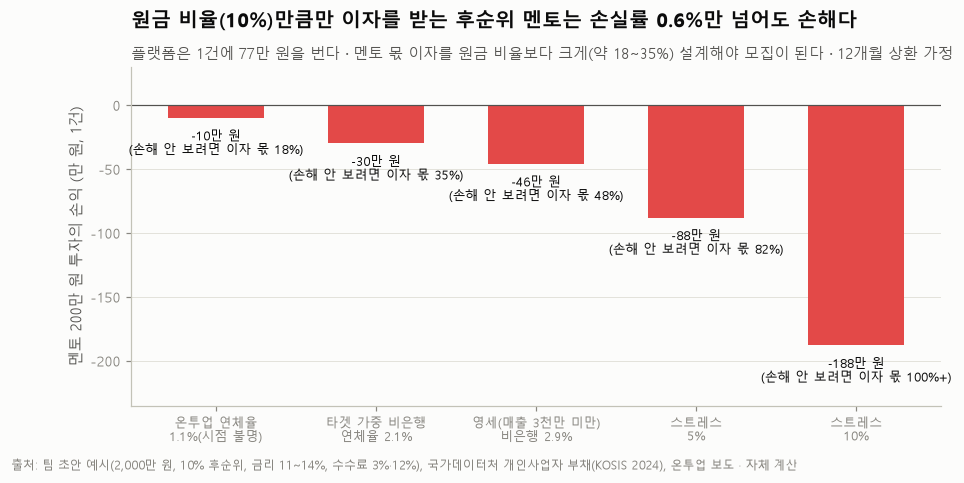

In [32]:
ue = M.draft_unit_economics()
p2 = ue["p2"]; bl = pd.DataFrame(p2["by_loss"])
print(f"플랫폼 수익 {p2['platform_revenue_won']/1e4:,.1f}만 원/건 (중개 {p2['platform_fee_won']/1e4:.0f}만 + 관리 {p2['mgmt_fee_won']/1e4:.1f}만) · "
      f"멘토 이자 {p2['mentor_interest_net_won']/1e4:.1f}만 원 · 멘토 손익분기 손실률 {p2['mentor_breakeven_loss_rate']*100:.2f}%")
print(bl.round(3).to_string(index=False))
p1 = pd.DataFrame(ue["p1"]); print("비자 스텝업 고객당 위험조정 마진(운영비 전):"); print(p1.round(3).to_string(index=False))
labels_l = {0.011: "온투업 연체율\n1.1%(시점 불명)", 0.021: "타겟 가중 비은행\n연체율 2.1%", 0.029: "영세(매출 3천만 미만)\n비은행 2.9%",
            0.05: "스트레스\n5%", 0.10: "스트레스\n10%"}
fig, ax = plt.subplots(figsize=(9.5, 4.0))
xs = np.arange(len(bl))
vals = bl.mentor_net_won / 1e4
ax.bar(xs, vals, color=[SERIES[0] if v >= 0 else "#e34948" for v in vals], width=0.6)
ax.axhline(0, color=C["ink2"], lw=0.8)
for xi, (v, need) in enumerate(zip(vals, bl.mentor_interest_share_needed)):
    ax.text(xi, v - 9, f"{v:,.0f}만 원\n(손해 안 보려면 이자 몫 {min(need, 1)*100:.0f}%{'+' if need > 1 else ''})", ha="center", va="top", fontsize=8.5)
ax.set_xticks(xs); ax.set_xticklabels([labels_l.get(round(l, 3), f"{l:.1%}") for l in bl.loss_rate], fontsize=8.5)
ax.set_ylim(-235, 30); ax.set_ylabel("멘토 200만 원 투자의 손익 (만 원, 1건)"); ax.grid(axis="x", visible=False)
ax.set_title(f"원금 비율(10%)만큼만 이자를 받는 후순위 멘토는 손실률 {p2['mentor_breakeven_loss_rate']*100:.1f}%만 넘어도 손해다")
V.subtitle(ax, f"플랫폼은 1건에 {p2['platform_revenue_won']/1e4:.0f}만 원을 번다 · 멘토 몫 이자를 원금 비율보다 크게(약 18~35%) 설계해야 모집이 된다 · 12개월 상환 가정")
V.finish(fig, FIG / "t25_p2p_mentor_economics.png",
         "팀 초안 예시(2,000만 원, 10% 후순위, 금리 11~14%, 수수료 3%·12%), 국가데이터처 개인사업자 부채(KOSIS 2024), 온투업 보도 · 자체 계산")

---
## 결론 — 제안서에 그대로 쓸 문장

In [33]:
sl = corr4.set_index("Y")
fam_dsr, wrk_dsr = g.loc["가족정착형", "DSR통과_3000"], g.loc["취업·학업형", "DSR통과_3000"]
lines = [
    ("Q1 타겟 수", f"외국인 사장님 {emp_core[2025]/1e4:.1f}만 명(범위 {ASSUME['신한카드 외국인 개인사업자 가맹점']/1e4:.1f}만~{nts.filers.iloc[-1]/1e4:.1f}만), "
                  f"연 {cagr_core:.0%} 증가해 2028년 {core_2028/1e4:.1f}만 명. 예비 사장님(사업 가능 체류자격) {biz_pool/1e4:.0f}만 명, "
                  f"상위 10개 시군구에 {reg.누적비중.iloc[9]:.0%} 집중."),
    ("Q1 잠재 수요", f"사업 가능 자격 취업자의 자영업률은 최대 {rate_elig:.1%}로 전체 평균 {kr:.1%}보다 낮다 → 격차만큼 약 {latent/1e4:.1f}만 명의 잠재 창업 수요."),
    ("Q2 돈이 된다", f"외국인 종소세 연 {nts.tax_eok.iloc[-1]:,.0f}억 원(1인당 {nts.tax_per_filer_만원.iloc[-1]:,.0f}만 원), "
                    f"한국발 개인송금 연 {rem25:.1f}조 원. 수익 시나리오 연 {scen.합계_억.iloc[0]:,.0f}억(보수)~{scen.합계_억.iloc[2]:,.0f}억(낙관), 기준 {scen.합계_억.iloc[1]:,.0f}억."),
    ("Q3 상환능력", f"사업 가능·가족정착형(F-4·F-5·F-6) 소득자의 {fam_dsr:.0f}%가 3,000만 원, {g.loc['가족정착형', 'DSR통과_5000']:.0f}%가 5,000만 원(연 6%·5년)을 DSR 40% 안에서 상환 가능 "
                   f"(취업·학업형 {g.loc['취업·학업형', 'DSR통과_5000']:.0f}%). 월 300만 원+ 소득 비중 {a1.iloc[3]['가족정착형(%)']:.0f}% vs {a1.iloc[3]['취업·학업형(%)']:.0f}%, 공과금 미납 경험 {g.loc['가족정착형', '공과금미납']:.1f}%."),
    ("Q4 정착 가능성", f"시군구 {len(m)}곳에서 사업 가능 외국인 비중 ↔ 10년+ 체류 ρ={sl.loc[YS['stay10'], 'spearman_rho']:.2f}, "
                      f"장기정착(10년+·귀화) ρ={sl.loc[YS['settle_long'], 'spearman_rho']:.2f} (규모 통제 후에도 p<0.001). "
                      f"가족정착형은 10년+ 체류 {a1.iloc[0]['가족정착형(%)']:.0f}% vs {a1.iloc[0]['취업·학업형(%)']:.0f}%, 계속 체류 희망 {a1.iloc[1]['가족정착형(%)']:.0f}%."),
]
summary = pd.DataFrame(lines, columns=["질문", "근거 문장"])
summary.to_csv(PROC / "target_evidence_summary.csv", index=False)
for q, t in lines:
    print(f"[{q}] {t}\n")

[Q1 타겟 수] 외국인 사장님 5.6만 명(범위 1.0만~25.3만), 연 9% 증가해 2028년 7.3만 명. 예비 사장님(사업 가능 체류자격) 109만 명, 상위 10개 시군구에 38% 집중.

[Q1 잠재 수요] 사업 가능 자격 취업자의 자영업률은 최대 12.3%로 전체 평균 19.6%보다 낮다 → 격차만큼 약 3.3만 명의 잠재 창업 수요.

[Q2 돈이 된다] 외국인 종소세 연 7,846억 원(1인당 310만 원), 한국발 개인송금 연 20.4조 원. 수익 시나리오 연 20억(보수)~267억(낙관), 기준 76억.

[Q3 상환능력] 사업 가능·가족정착형(F-4·F-5·F-6) 소득자의 91%가 3,000만 원, 69%가 5,000만 원(연 6%·5년)을 DSR 40% 안에서 상환 가능 (취업·학업형 62%). 월 300만 원+ 소득 비중 47% vs 30%, 공과금 미납 경험 3.5%.

[Q4 정착 가능성] 시군구 208곳에서 사업 가능 외국인 비중 ↔ 10년+ 체류 ρ=0.89, 장기정착(10년+·귀화) ρ=0.79 (규모 통제 후에도 p<0.001). 가족정착형은 10년+ 체류 65% vs 8%, 계속 체류 희망 97%.



**한계** — (1) 외국인 사장님을 직접 세는 공개 통계가 없어 세 자료로 범위를 잡았다. (2) DSR은 체류자격 전체 소득 분포를 쓴 대리 추정이다.
(3) 지역 상관은 생태학적 상관이며, 사업 가능 자격에 장기체류형(F-5·F-6)이 포함돼 일부는 구성 효과다 — 인과가 아니라 '이 고객군이 남는 고객'이라는 근거로 쓴다.
(4) 지역 자료 시점이 2026.9(법무부)와 2024.11(행안부)로 다르다. (5) 수익 시나리오의 침투율·마진·대손율은 가정이다.
MDIS 마이크로데이터를 받으면 자영업자 개인 단위로 소득·송금·체류기간을 직접 교차해 Q1·Q3를 정밀화할 수 있다.